# Context responsiveness: malignant markers versus query-type native markers

This focused notebook reuses the completed 300-query stratified experiment’s saved predictions. It compares the authors’ **32 breast-cancer-panel genes** (positives) against **the authors’ markers for the query cell type** (negatives), from sheet **ST 4** of `41592_2026_3089_MOESM4_ESM.xlsx`. It does not retrain, resample queries/contexts, alter the original notebook, or substitute all nonpanel genes as negatives.

For each original query, retain only genes with raw counts >0, keeping the positive and negative sets fixed across its context swaps. AUROC is the fraction of malignant/native gene pairs in which the malignant gene has the higher Syndri admixture score, with half credit for ties. Higher means malignant-panel genes are preferentially ranked as admixture relative to native markers. Use `ΔAUROC = remapped − original`. Saved probabilities and unclipped logits give identical rankings.

All existing **nine query strata** are retained: low/medium/high 32-panel transcript burden × original malignant-neighbor group 0/1–2/3–5. Burden quantiles remain the original per-slice/per-exact-type definitions, not recalculated after native-marker filtering. Encoded contexts contain the same five nearest eligible different-cell-type neighbors. Each selected donor appears once; unchanged duplicate controls are excluded from response curves.

The only analyses included are those affected by the changed negative marker set: coverage/baseline scores, burden-stratified AUROC curves, matched-marker per-gene response heatmaps, and controlled/native slope comparisons. These describe model responsiveness, not biological ground truth.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RUN = Path("/home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220")
SOURCE_RUN = Path("/home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748")
if str(RUN) not in sys.path:
    sys.path.insert(0, str(RUN))
from native_marker_analysis import compute_native_marker_analysis
print("New outputs:", RUN)
print("Existing predictions:", SOURCE_RUN / "predictions")


New outputs: /home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220
Existing predictions: /home/jwinchel/Syndri/context_analysis/results/all_type_responsiveness_stratified300_20261019_162748/predictions


## Authors’ marker mapping and limitations

- All three T-cell query types use all rows annotated **T cells** in the authors’ `Annotation` column. This includes general/canonical, cytotoxic, exhausted, regulatory, and immune-response annotations (35 genes).
- NK, macrophage, monocyte, mast, DC, endothelial, fibroblast, and smooth-muscle sets use their corresponding `Annotation_DB` entries. The two fibroblast query types share the general fibroblast set; plasmacytoid DC uses the authors’ general dendritic-cell set.
- Plasma cells use the exact **plasma cell** entry, **TNFRSF17 only**. There are no B-cell queries in this experiment. The B-cell marker set is not silently substituted for plasma markers.
- **Pericytes are excluded:** ST 4 has no pericyte annotation, and no smooth-muscle proxy is invented. Stromal curves therefore represent the available fibroblast and smooth-muscle types.
- Positives and native negatives must be disjoint. A query without at least one expressed malignant marker **and** one expressed native marker has undefined AUROC and is excluded. Unexpressed genes are not assigned low scores or zero ranks.

This filtering changes the eligible cohort relative to the all-nonpanel comparison. Single/small native sets can cause substantial missingness or coarse scores; inspect coverage before interpreting curves.


In [2]:
native_marker_mapping = pd.read_csv(RUN / "query_native_marker_mapping.csv")
display(native_marker_mapping)


,query_cell_type,selection_column,selection_value,n_authors_native_markers,native_genes,status
0,"CD4-positive, alpha-beta memory T cell",Annotation,T cells,35,CCL5; CCR7; CD274; CD3E; CD3G; CD4; CD69; CD8A...,mapped
1,cytotoxic T cell,Annotation,T cells,35,CCL5; CCR7; CD274; CD3E; CD3G; CD4; CD69; CD8A...,mapped
2,natural T-regulatory cell,Annotation,T cells,35,CCL5; CCR7; CD274; CD3E; CD3G; CD4; CD69; CD8A...,mapped
3,natural killer cell,Annotation_DB,NK cell,8,CD247; FCER1G; GNLY; KLRD1; KLRF1; NCAM1; NKG7...,mapped
4,plasma cell,Annotation_DB,plasma cell,1,TNFRSF17,mapped
5,classical monocyte,Annotation_DB,monocyte,3,CD14; FCGR3A; S100A8,mapped
6,macrophage,Annotation_DB,macrophage,26,AIF1; APOC1; BASP1; C1QA; C1QC; CD163; CD68; C...,mapped
7,mast cell,Annotation_DB,mast cell,3,CPA3; CTSG; TPSAB1,mapped
8,plasmacytoid dendritic cell,Annotation_DB,dendritic cell,9,ADGRE5; CD83; CLEC9A; FCER1A; IL2RG; IL3RA; IT...,mapped
9,capillary endothelial cell,Annotation_DB,endothelial cell,11,AKR1C3; ANGPT2; AQP1; CD93; ESM1; PECAM1; SOX1...,mapped


## Compute matched-marker scores from existing predictions

This cell reads saved probabilities and raw query counts once per section, saves per-query/context AUROC and gene-specific native-marker win changes, and preserves all sampling metadata. Outputs are cached in this notebook’s separate result directory. Rerunning with the same definitions uses that cache.


In [3]:
native_auroc_out, native_gene_out = compute_native_marker_analysis(RUN)
print(json.loads((RUN / "analysis_complete.json").read_text()))


{'n_queries': 33567, 'n_valid_queries': 27739, 'n_rows': 1069703, 'unchanged_controls_zero': True}


## Coverage and original-context baseline AUROC

Queries are counted once. The coverage table includes all 14 original query types, including pericyte exclusions and queries missing either expressed marker class. Baseline summaries report the surviving cohort; do not compare them with the older all-nonpanel baseline without accounting for the changed gene sets and query eligibility.


In [4]:
eligibility = pd.read_csv(RUN / "query_marker_eligibility.csv.gz")
coverage = eligibility.groupby(["query_cell_type", "status"], observed=True).size().unstack(fill_value=0)
coverage["total_queries"] = coverage.sum(axis=1)
coverage["fraction_valid"] = coverage.get("valid", 0) / coverage.total_queries
display(coverage)
coverage.to_csv(RUN / "native_marker_coverage_summary.csv")
scored_originals = pd.read_csv(native_auroc_out / "marker_auroc_context_responses.csv.gz",
    usecols=["slice", "query_cell_id", "query_cell_type", "context_kind", "marker_auroc", "query_burden_quantile"])
scored_originals = scored_originals.loc[scored_originals.context_kind.eq("original")]
assert not scored_originals.duplicated(["slice", "query_cell_id"]).any()
baseline = scored_originals.groupby(["query_cell_type", "query_burden_quantile"], observed=True).marker_auroc.agg(
    n_queries="count", median="median", mean="mean", q25=lambda s:s.quantile(.25), q75=lambda s:s.quantile(.75)).reset_index()
baseline.to_csv(RUN / "baseline_native_marker_auroc.csv", index=False)
display(baseline)


status,no_expressed_malignant_marker,no_expressed_native_marker,no_native_annotation,valid,total_queries,fraction_valid
query_cell_type,,,,,,
"CD4-positive, alpha-beta memory T cell",46,4,0,2350,2400,0.979167
capillary endothelial cell,13,38,0,2349,2400,0.978750
classical monocyte,26,462,0,1912,2400,0.796667
cytotoxic T cell,31,19,0,2350,2400,0.979167
fibroblast of breast,11,44,0,2345,2400,0.977083
fibroblast of lung,5,9,0,2386,2400,0.994167
macrophage,13,1,0,2386,2400,0.994167
mast cell,18,261,0,2121,2400,0.883750
natural T-regulatory cell,32,8,0,2360,2400,0.983333


,query_cell_type,query_burden_quantile,n_queries,median,mean,q25,q75
0,"CD4-positive, alpha-beta memory T cell",high,947,0.840909,0.831711,0.750000,0.923303
1,"CD4-positive, alpha-beta memory T cell",low,652,0.733854,0.728934,0.615385,0.857143
2,"CD4-positive, alpha-beta memory T cell",medium,751,0.756410,0.754692,0.666667,0.857143
3,capillary endothelial cell,high,792,0.950490,0.930541,0.885216,1.000000
4,capillary endothelial cell,low,767,0.937500,0.915070,0.873016,1.000000
5,capillary endothelial cell,medium,790,0.939394,0.923846,0.880000,1.000000
6,classical monocyte,high,611,0.923077,0.875382,0.812500,1.000000
7,classical monocyte,low,631,0.833333,0.796751,0.666667,1.000000
8,classical monocyte,medium,670,0.888889,0.841059,0.750000,1.000000
9,cytotoxic T cell,high,827,0.944444,0.928416,0.896537,0.987013


## Burden panels: original-context strata kept separate

Three panels show original low/medium/high burden. Curves distinguish original malignant-neighbor groups 0, 1–2, 3–5. Average donor responses within query at each integer Δ malignant count; take query medians within exact type/section/burden/original group (≥5 queries), then medians across supported types within sections. Curves are section medians and ribbons section IQR (≥3 sections). Queries/types with no matched-marker support remain missing; no compensation or extrapolation.


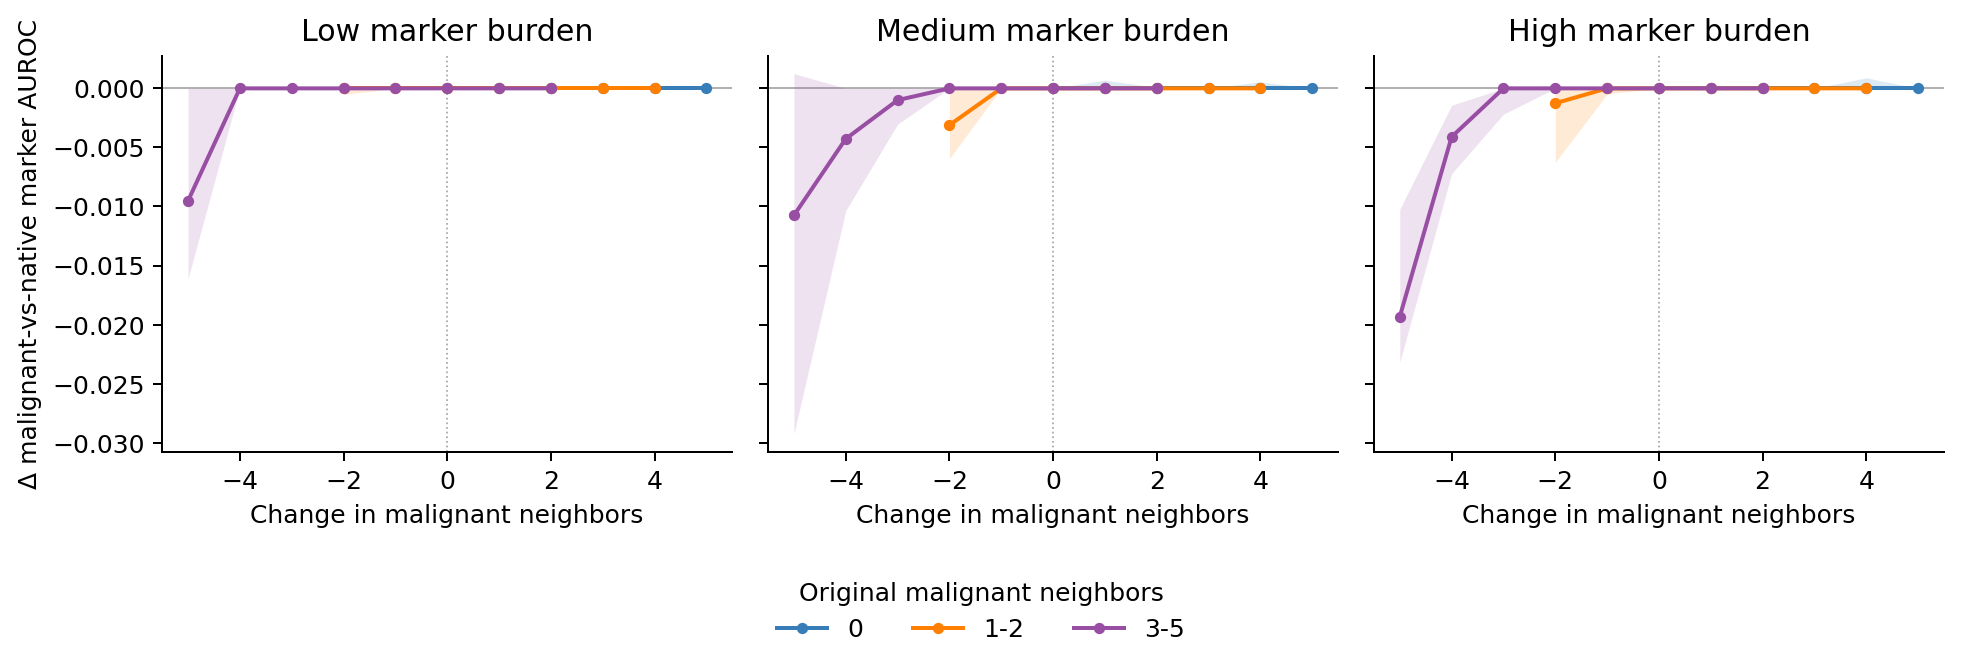

Saved: /home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220/burden_stratified_context_auroc_response


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

BURDEN_QUERY_TYPES = None  # All supported query types, or an explicit list.
BURDEN_MIN_QUERIES = 5  # Per slice/type/burden/original-neighbor group/x value.
BURDEN_MIN_SECTIONS = 3
burden_run = Path("/home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220")
import sys
if str(burden_run) not in sys.path:
    sys.path.insert(0, str(burden_run))
from marker_auroc_responses import compute_marker_auroc_responses
compute_marker_auroc_responses(burden_run)
burden_output = burden_run / "burden_stratified_context_auroc_response"
burden_output.mkdir(exist_ok=True)
burden_data = pd.read_csv(burden_run / "marker_auroc_context_responses" / "marker_auroc_context_responses.csv.gz")
# Include the original row only when that query is a selected shared-panel donor;
# exclude the duplicated unchanged control. This retains every selected donor once.
burden_data = burden_data.loc[
    burden_data.context_selected_for_shared_panel.eq(True)
    & burden_data.context_kind.ne("unchanged_control")
    & burden_data.query_burden_quantile.isin(["low", "medium", "high"])
].copy()
if BURDEN_QUERY_TYPES is not None:
    burden_data = burden_data.loc[burden_data.query_cell_type.isin(BURDEN_QUERY_TYPES)].copy()
burden_data["delta_malignant_neighbors"] = (
    burden_data.context_malignant_token_count - burden_data.query_malignant_token_count
).astype(int)
burden_data = burden_data.loc[np.isfinite(burden_data.delta_marker_auroc)]
if burden_data.empty:
    raise ValueError("No finite responses for the selected query types and burden quantiles")
burden_keys = ["slice", "query_cell_type", "query_burden_quantile", "query_neighbor_level", "delta_malignant_neighbors"]
# Repeated donors at the same malignant count receive equal weight within query.
burden_query = burden_data.groupby(burden_keys + ["query_cell_id"], observed=True).agg(
    delta_marker_auroc=("delta_marker_auroc", "mean"), n_contexts=("delta_marker_auroc", "size")
).reset_index()
burden_type = burden_query.groupby(burden_keys, observed=True).agg(
    delta_marker_auroc=("delta_marker_auroc", "median"), n_queries=("query_cell_id", "nunique")
).reset_index()
burden_supported = burden_type.loc[burden_type.n_queries.ge(BURDEN_MIN_QUERIES)]
burden_section_keys = ["slice", "query_burden_quantile", "query_neighbor_level", "delta_malignant_neighbors"]
burden_sections = burden_supported.groupby(burden_section_keys, observed=True).agg(
    delta_marker_auroc=("delta_marker_auroc", "median"), n_cell_types=("query_cell_type", "nunique")
).reset_index()
burden_summary = burden_sections.groupby(burden_section_keys[1:], observed=True).agg(
    median=("delta_marker_auroc", "median"),
    q25=("delta_marker_auroc", lambda s: s.quantile(.25)),
    q75=("delta_marker_auroc", lambda s: s.quantile(.75)),
    n_sections=("slice", "nunique")
).reset_index()
for name, table in [("query_responses", burden_query), ("cell_type_section_responses", burden_type),
                    ("section_responses", burden_sections), ("summary", burden_summary)]:
    table.to_csv(burden_output / f"{name}.csv.gz", index=False, compression="gzip")

burden_colors = {"0": "#377eb8", "1-2": "#ff7f00", "3-5": "#984ea3"}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharex=True, sharey=True, dpi=180)
for ax, quantile in zip(axes, ["low", "medium", "high"]):
    for group, color in burden_colors.items():
        current = burden_summary.loc[
            burden_summary.query_burden_quantile.eq(quantile)
            & burden_summary.query_neighbor_level.eq(group)
        ].set_index("delta_malignant_neighbors").reindex(range(-5, 6))
        # Reindexing prevents lines bridging unsupported integer x values.
        current.loc[current.n_sections.fillna(0).lt(BURDEN_MIN_SECTIONS), ["median", "q25", "q75"]] = np.nan
        x = current.index.to_numpy()
        ax.plot(x, current["median"], marker="o", ms=3.5, lw=1.6, color=color, label=group)
        ax.fill_between(x, current.q25.to_numpy(float), current.q75.to_numpy(float), color=color, alpha=.16, linewidth=0)
    ax.axhline(0, color=".65", lw=.7, zorder=0)
    ax.axvline(0, color=".65", lw=.7, ls=":", zorder=0)
    ax.set_title(f"{quantile.capitalize()} marker burden")
    ax.set_xlabel("Change in malignant neighbors")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Δ malignant-vs-native marker AUROC")
fig.legend(*axes[0].get_legend_handles_labels(), title="Original malignant neighbors", loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(.5, -.04))
fig.tight_layout(rect=[0, .13, 1, 1])
for suffix in ["png", "pdf"]:
    fig.savefig(burden_output / f"burden_quantile_delta_marker_auroc.{suffix}", bbox_inches="tight")
plt.show()
print("Saved:", burden_output)


## Superclass-specific AUROC curves

Four rows: Lymphoid, Myeloid, Stromal, Vascular; three columns: burden. Preserve original-neighbor curves. Within each type/section/stratum/x, take query medians (≥5 queries); **average exact-type medians equally within superclass/section**, then summarize sections by median and IQR (≥3). Pericytes do not contribute; families are unchanged otherwise. Native-marker eligibility is type-specific before pooling.


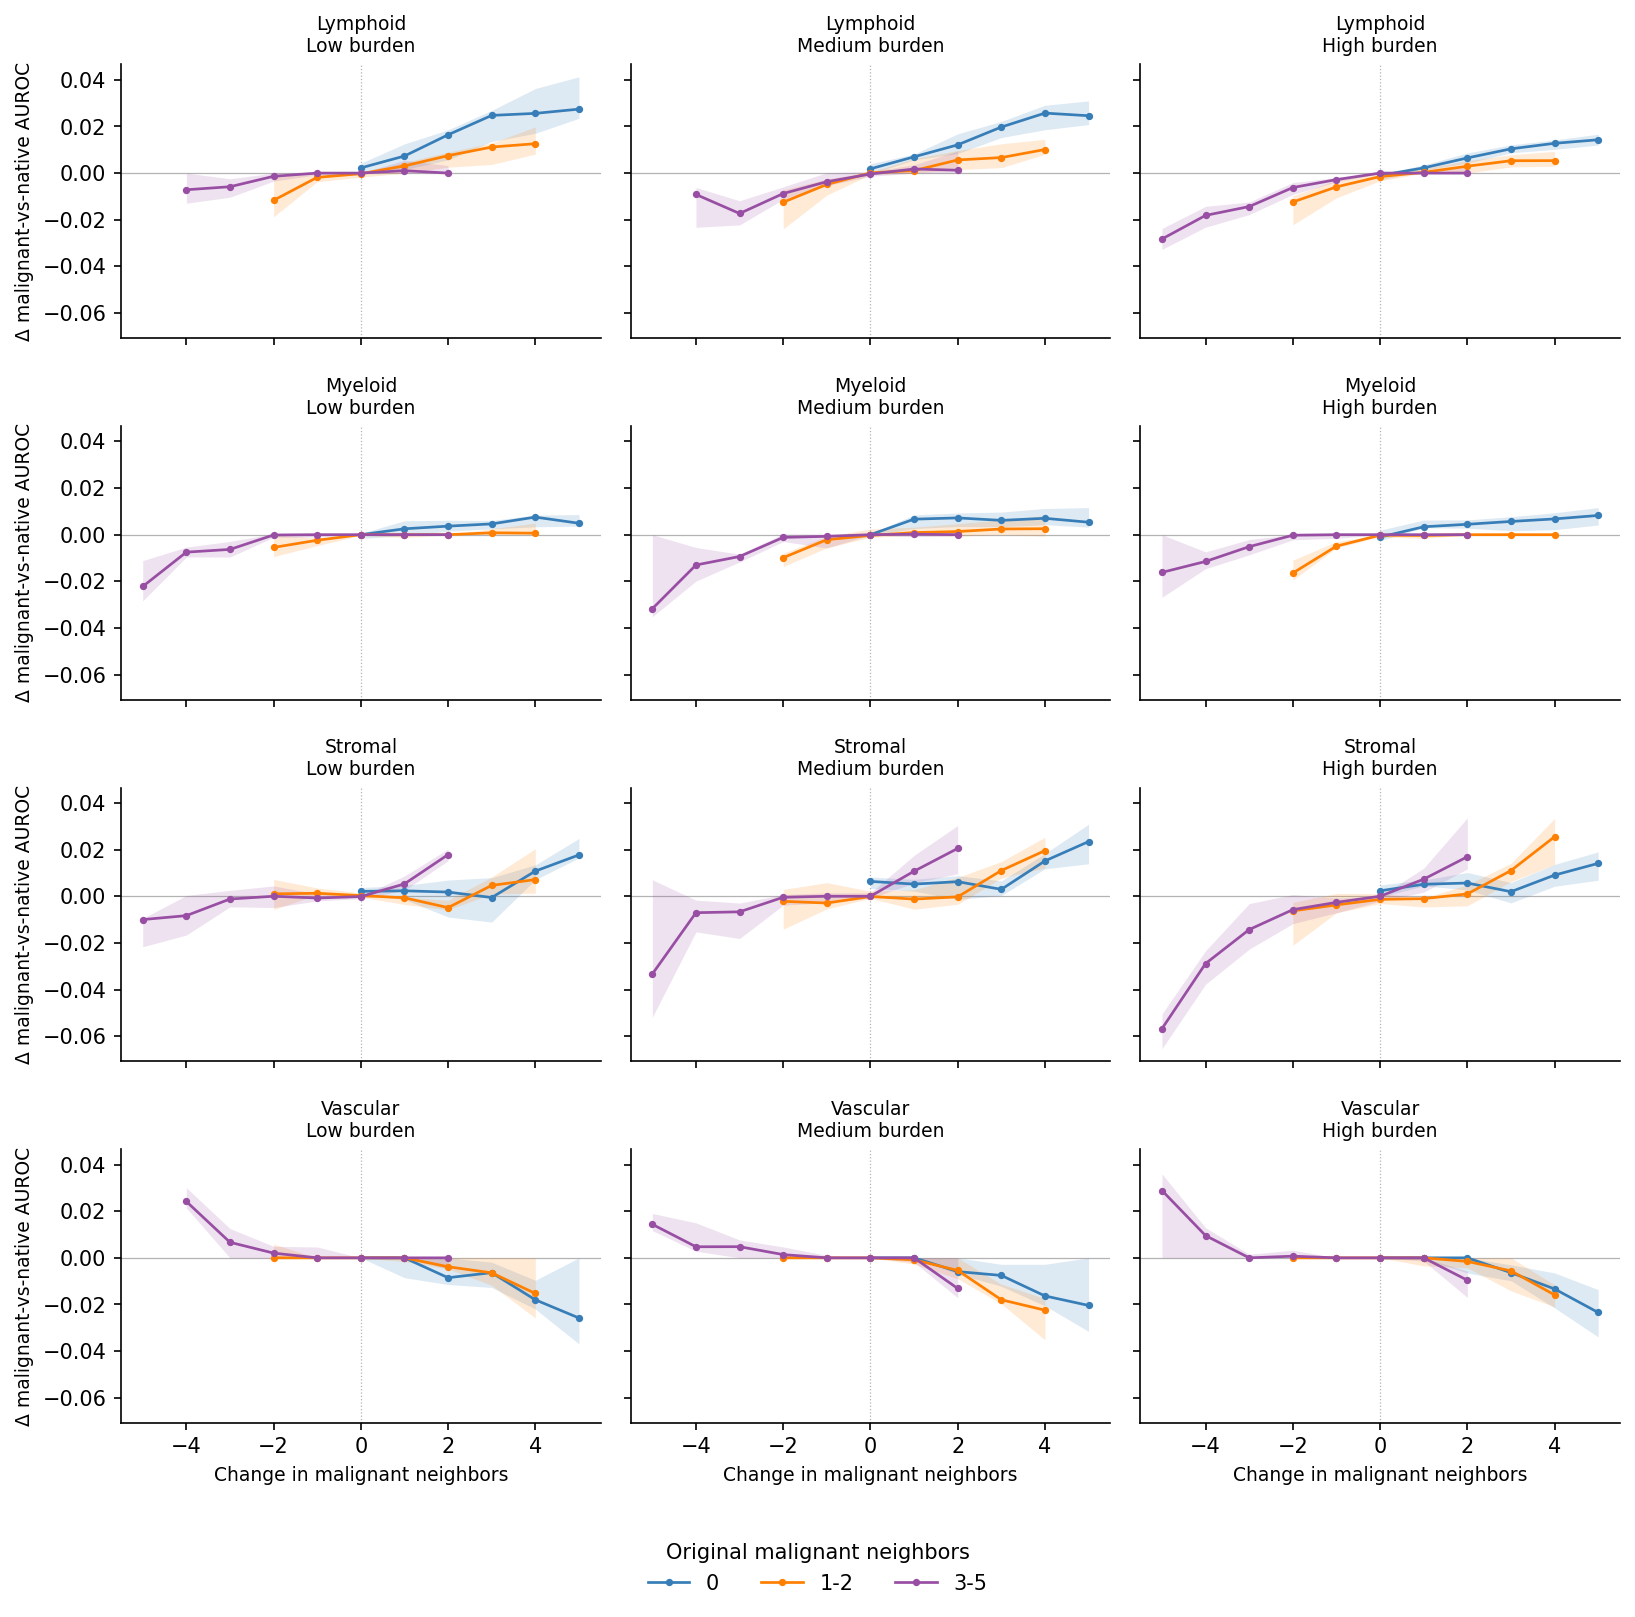

Saved grid for 4 cell families to /home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220/burden_stratified_context_auroc_response


In [6]:
# One cell family per row; equal-weight mean of supported cell-type medians per section.
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

BURDEN_FAMILY_QUERY_TYPES = None  # Optional subset of exact cell types contributing to families.
BURDEN_FAMILY_ORDER = ["Lymphoid", "Myeloid", "Stromal", "Vascular"]
BURDEN_FAMILY_MAP = {'CD4-positive, alpha-beta memory T cell': 'Lymphoid', 'cytotoxic T cell': 'Lymphoid', 'natural T-regulatory cell': 'Lymphoid', 'natural killer cell': 'Lymphoid', 'plasma cell': 'Lymphoid', 'macrophage': 'Myeloid', 'classical monocyte': 'Myeloid', 'plasmacytoid dendritic cell': 'Myeloid', 'mast cell': 'Myeloid', 'fibroblast of breast': 'Stromal', 'fibroblast of lung': 'Stromal', 'pericyte': 'Stromal', 'smooth muscle cell': 'Stromal', 'capillary endothelial cell': 'Vascular'}
BURDEN_FAMILY_MIN_QUERIES = 5
BURDEN_FAMILY_MIN_SECTIONS = 3
burden_family_run = Path("/home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220")
import sys
if str(burden_family_run) not in sys.path:
    sys.path.insert(0, str(burden_family_run))
from marker_auroc_responses import compute_marker_auroc_responses
compute_marker_auroc_responses(burden_family_run)
burden_family_out = burden_family_run / "burden_stratified_context_auroc_response"
# Read the full responses so this grid is independent of the pooled plot's type filter.
burden_family_rows = pd.read_csv(burden_family_run / "marker_auroc_context_responses" / "marker_auroc_context_responses.csv.gz")
burden_family_rows = burden_family_rows.loc[
    burden_family_rows.context_selected_for_shared_panel.eq(True)
    & burden_family_rows.context_kind.ne("unchanged_control")
    & burden_family_rows.query_burden_quantile.isin(["low", "medium", "high"])
    & np.isfinite(burden_family_rows.delta_marker_auroc)
].copy()
burden_family_rows["delta_malignant_neighbors"] = (
    burden_family_rows.context_malignant_token_count - burden_family_rows.query_malignant_token_count
).astype(int)
burden_family_types = sorted(burden_family_rows.query_cell_type.unique()) if BURDEN_FAMILY_QUERY_TYPES is None else list(BURDEN_FAMILY_QUERY_TYPES)
missing_types = set(burden_family_types) - set(burden_family_rows.query_cell_type)
if missing_types or not burden_family_types:
    raise ValueError(f"Empty selection or unavailable cell types: {missing_types}")
burden_family_keys = ["slice", "query_cell_type", "query_burden_quantile", "query_neighbor_level", "delta_malignant_neighbors"]
burden_family_queries = burden_family_rows.groupby(burden_family_keys + ["query_cell_id"], observed=True).delta_marker_auroc.mean().reset_index()
burden_family_sections = burden_family_queries.groupby(burden_family_keys, observed=True).agg(
    delta_marker_auroc=("delta_marker_auroc", "median"), n_queries=("query_cell_id", "nunique")
).reset_index()
# Keep per-type query support thresholds before averaging types within a family.
burden_family_sections["query_family"] = burden_family_sections.query_cell_type.map(BURDEN_FAMILY_MAP)
if burden_family_sections.query_family.isna().any():
    raise ValueError("Unmapped query cell types; update BURDEN_FAMILY_MAP explicitly")
if BURDEN_FAMILY_QUERY_TYPES is not None:
    burden_family_sections = burden_family_sections.loc[burden_family_sections.query_cell_type.isin(BURDEN_FAMILY_QUERY_TYPES)]
burden_family_type_sections = burden_family_sections.copy()
burden_family_sections = burden_family_sections.loc[burden_family_sections.n_queries.ge(BURDEN_FAMILY_MIN_QUERIES)].groupby(
    ["slice", "query_family", "query_burden_quantile", "query_neighbor_level", "delta_malignant_neighbors"], observed=True
).agg(delta_marker_auroc=("delta_marker_auroc", "mean"),
      n_cell_types=("query_cell_type", "nunique"), n_queries=("n_queries", "sum")).reset_index()
burden_family_keys = ["slice", "query_family", "query_burden_quantile", "query_neighbor_level", "delta_malignant_neighbors"]
burden_family_types = [family for family in BURDEN_FAMILY_ORDER if family in set(burden_family_sections.query_family)]
burden_family_summary = burden_family_sections.loc[burden_family_sections.n_queries.ge(BURDEN_FAMILY_MIN_QUERIES)].groupby(
    burden_family_keys[1:], observed=True
).agg(median=("delta_marker_auroc", "median"),
      q25=("delta_marker_auroc", lambda s: s.quantile(.25)),
      q75=("delta_marker_auroc", lambda s: s.quantile(.75)),
      n_sections=("slice", "nunique")).reset_index()
burden_family_out.mkdir(exist_ok=True)
pd.DataFrame(list(BURDEN_FAMILY_MAP.items()), columns=["query_cell_type", "query_family"]).to_csv(burden_family_out / "cell_family_mapping.csv", index=False)
burden_family_type_sections.to_csv(burden_family_out / "cell_family_contributing_type_responses.csv.gz", index=False, compression="gzip")
burden_family_sections.to_csv(burden_family_out / "cell_family_grid_section_responses.csv.gz", index=False, compression="gzip")
burden_family_summary.to_csv(burden_family_out / "cell_family_grid_summary.csv", index=False)
fig, axes = plt.subplots(len(burden_family_types), 3, figsize=(11, 2.7 * len(burden_family_types)),
                         sharex=True, sharey=True, squeeze=False, dpi=150)
burden_family_colors = {"0": "#377eb8", "1-2": "#ff7f00", "3-5": "#984ea3"}
for row, query_type in enumerate(burden_family_types):
    for col, quantile in enumerate(["low", "medium", "high"]):
        ax = axes[row, col]
        for group, color in burden_family_colors.items():
            current = burden_family_summary.loc[
                burden_family_summary.query_family.eq(query_type)
                & burden_family_summary.query_burden_quantile.eq(quantile)
                & burden_family_summary.query_neighbor_level.eq(group)
            ].set_index("delta_malignant_neighbors").reindex(range(-5, 6))
            current.loc[current.n_sections.fillna(0).lt(BURDEN_FAMILY_MIN_SECTIONS), ["median", "q25", "q75"]] = np.nan
            ax.plot(current.index, current["median"], color=color, marker="o", ms=2.5, lw=1.3, label=group)
            ax.fill_between(current.index.to_numpy(), current.q25.to_numpy(float), current.q75.to_numpy(float), color=color, alpha=.16, linewidth=0)
        ax.axhline(0, color=".7", lw=.6, zorder=0)
        ax.axvline(0, color=".7", lw=.6, ls=":", zorder=0)
        ax.set_title(f"{query_type}\n{quantile.capitalize()} burden", fontsize=9)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
        ax.spines[["top", "right"]].set_visible(False)
        if col == 0:
            ax.set_ylabel("Δ malignant-vs-native AUROC", fontsize=9)
        if row == len(burden_family_types) - 1:
            ax.set_xlabel("Change in malignant neighbors", fontsize=9)
fig.legend(*axes[0, 0].get_legend_handles_labels(), title="Original malignant neighbors", loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(.5, 0))
fig.tight_layout(rect=[0, .065, 1, 1], h_pad=1.5)
for suffix in ["png", "pdf"]:
    fig.savefig(burden_family_out / f"cell_family_burden_quantile_delta_marker_auroc.{suffix}", bbox_inches="tight")
plt.show()
print(f"Saved grid for {len(burden_family_types)} cell families to {burden_family_out}")


## Condensed superclass curves, balancing original-context strata

For each section/superclass/burden/x, average available original-neighbor stratum responses equally, after the ≥3-section stratum-support gate. Lines show the section median, ribbons the section IQR. Four superclass curves share each burden panel, using the Xenium UMAP family colors. Contributor identities/counts are saved; they can change with x because some original-context strata cannot produce particular count changes.


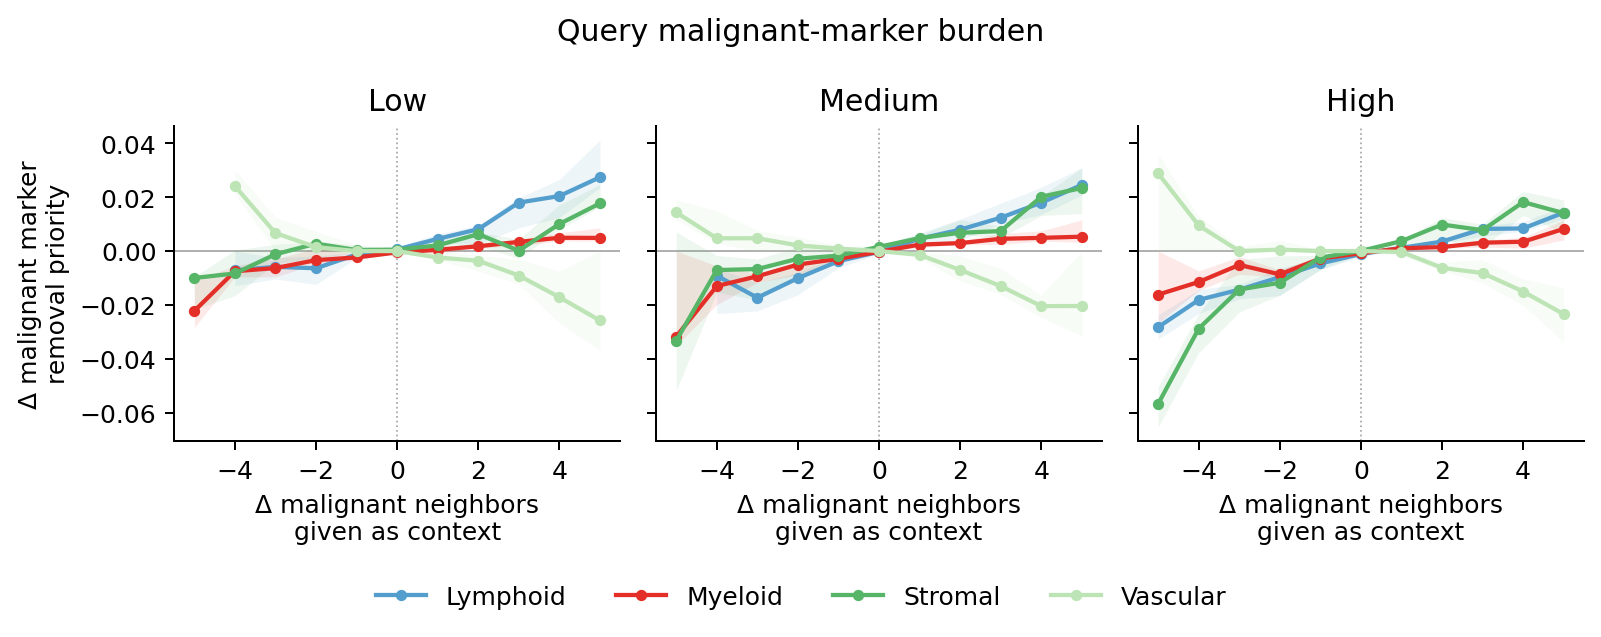

Saved equal-stratum superclass curves and contributing-strata tables: /home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220/burden_stratified_context_auroc_response


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

COMBINED_AUROC_RUN = Path("/home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220")
COMBINED_AUROC_MIN_SECTIONS = 3
COMBINED_AUROC_FAMILY_ORDER = ["Lymphoid", "Myeloid", "Stromal", "Vascular"]
# Exact representative shades from Figure2_UMAPs_Xenium.ipynb: lymphoid blue,
# myeloid/innate red, stromal/vascular greens (vascular uses capillary endothelial).
COMBINED_AUROC_COLORS = {'Lymphoid': '#539ecd', 'Myeloid': '#e32f27', 'Stromal': '#56b567', 'Vascular': '#bce4b5'}
combined_auroc_out = COMBINED_AUROC_RUN / "burden_stratified_context_auroc_response"
combined_source = combined_auroc_out / "cell_family_grid_section_responses.csv.gz"
if not combined_source.exists():
    raise FileNotFoundError("Run the preceding cell-family AUROC grid first: " + str(combined_source))
combined_family_sections = pd.read_csv(combined_source, dtype={"query_neighbor_level": str})
combined_stratum_keys = ["query_family", "query_burden_quantile", "query_neighbor_level", "delta_malignant_neighbors"]
# Preserve the separate original-context curves: each is the section median
# of equal-weight type summaries, as in the preceding superclass grid.
combined_stratum_curves = combined_family_sections.groupby(combined_stratum_keys, observed=True).agg(
    stratum_delta_auroc=("delta_marker_auroc", "median"), n_sections=("slice", "nunique")
).reset_index()
combined_stratum_curves["contributes"] = (
    combined_stratum_curves.n_sections.ge(COMBINED_AUROC_MIN_SECTIONS)
    & np.isfinite(combined_stratum_curves.stratum_delta_auroc)
)
combined_supported = combined_stratum_curves.loc[combined_stratum_curves.contributes].copy()
combined_keys = ["query_family", "query_burden_quantile", "delta_malignant_neighbors"]
# Average original-context strata equally within each section at each x.
# Retain the same >=3-section support gate for each stratum/x combination.
combined_supported_sections = combined_family_sections.merge(
    combined_supported[combined_stratum_keys], on=combined_stratum_keys,
    how="inner", validate="many_to_one")
combined_section_curves = combined_supported_sections.groupby(["slice"] + combined_keys, observed=True).agg(
    delta_marker_auroc=("delta_marker_auroc", "mean"),
    n_original_context_strata=("query_neighbor_level", "nunique"),
    contributing_strata=("query_neighbor_level", lambda s: ", ".join(v for v in ["0", "1-2", "3-5"] if v in set(s)))
).reset_index()
combined_auroc_curves = combined_section_curves.groupby(combined_keys, observed=True).agg(
    delta_marker_auroc=("delta_marker_auroc", "median"),
    q25=("delta_marker_auroc", lambda s: s.quantile(.25)),
    q75=("delta_marker_auroc", lambda s: s.quantile(.75)),
    n_sections=("slice", "nunique"),
    min_original_context_strata=("n_original_context_strata", "min"),
    max_original_context_strata=("n_original_context_strata", "max")
).reset_index()
assert combined_section_curves.n_original_context_strata.between(1, 3).all()
combined_stratum_curves.to_csv(combined_auroc_out / "combined_family_auroc_stratum_support.csv", index=False)
combined_section_curves.to_csv(combined_auroc_out / "combined_family_auroc_section_curves.csv", index=False)
combined_auroc_curves.to_csv(combined_auroc_out / "combined_family_auroc_curves.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(9, 3.5), sharex=True, sharey=True, dpi=180)
for ax, burden in zip(axes, ["low", "medium", "high"]):
    for family in COMBINED_AUROC_FAMILY_ORDER:
        current = combined_auroc_curves.loc[
            combined_auroc_curves.query_family.eq(family)
            & combined_auroc_curves.query_burden_quantile.eq(burden)
        ].set_index("delta_malignant_neighbors").reindex(range(-5, 6))
        current.loc[current.n_sections.fillna(0).lt(COMBINED_AUROC_MIN_SECTIONS), ["delta_marker_auroc", "q25", "q75"]] = np.nan
        ax.fill_between(current.index.to_numpy(), current.q25.to_numpy(float), current.q75.to_numpy(float),
                        color=COMBINED_AUROC_COLORS[family], alpha=.10, linewidth=0)
        ax.plot(current.index, current.delta_marker_auroc, marker="o", ms=3.5,
                lw=1.7, color=COMBINED_AUROC_COLORS[family], label=family)
    ax.axhline(0, color=".65", lw=.7, zorder=0)
    ax.axvline(0, color=".65", lw=.7, ls=":", zorder=0)
    ax.set_title(f"{burden.capitalize()}")
    ax.set_xlabel("Δ malignant neighbors\ngiven as context")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Δ malignant marker\nremoval priority")
fig.suptitle("Query malignant-marker burden")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4,
           frameon=False, bbox_to_anchor=(.5, .005))
fig.tight_layout(rect=[0, .10, 1, 1])
for suffix in ["png", "pdf"]:
    fig.savefig(combined_auroc_out / f"combined_superclass_burden_delta_auroc.{suffix}", bbox_inches="tight")
plt.show()
print("Saved equal-stratum superclass curves and contributing-strata tables:", combined_auroc_out)


## Exact-cell-type AUROC response grid

Same three burden columns, separate original-context curves, ≥5 query support per exact-type/section point, and section median/IQR with ≥3 sections. Only types with finite matched-marker AUROC appear. Use `BURDEN_GRID_QUERY_TYPES` to select a smaller set.


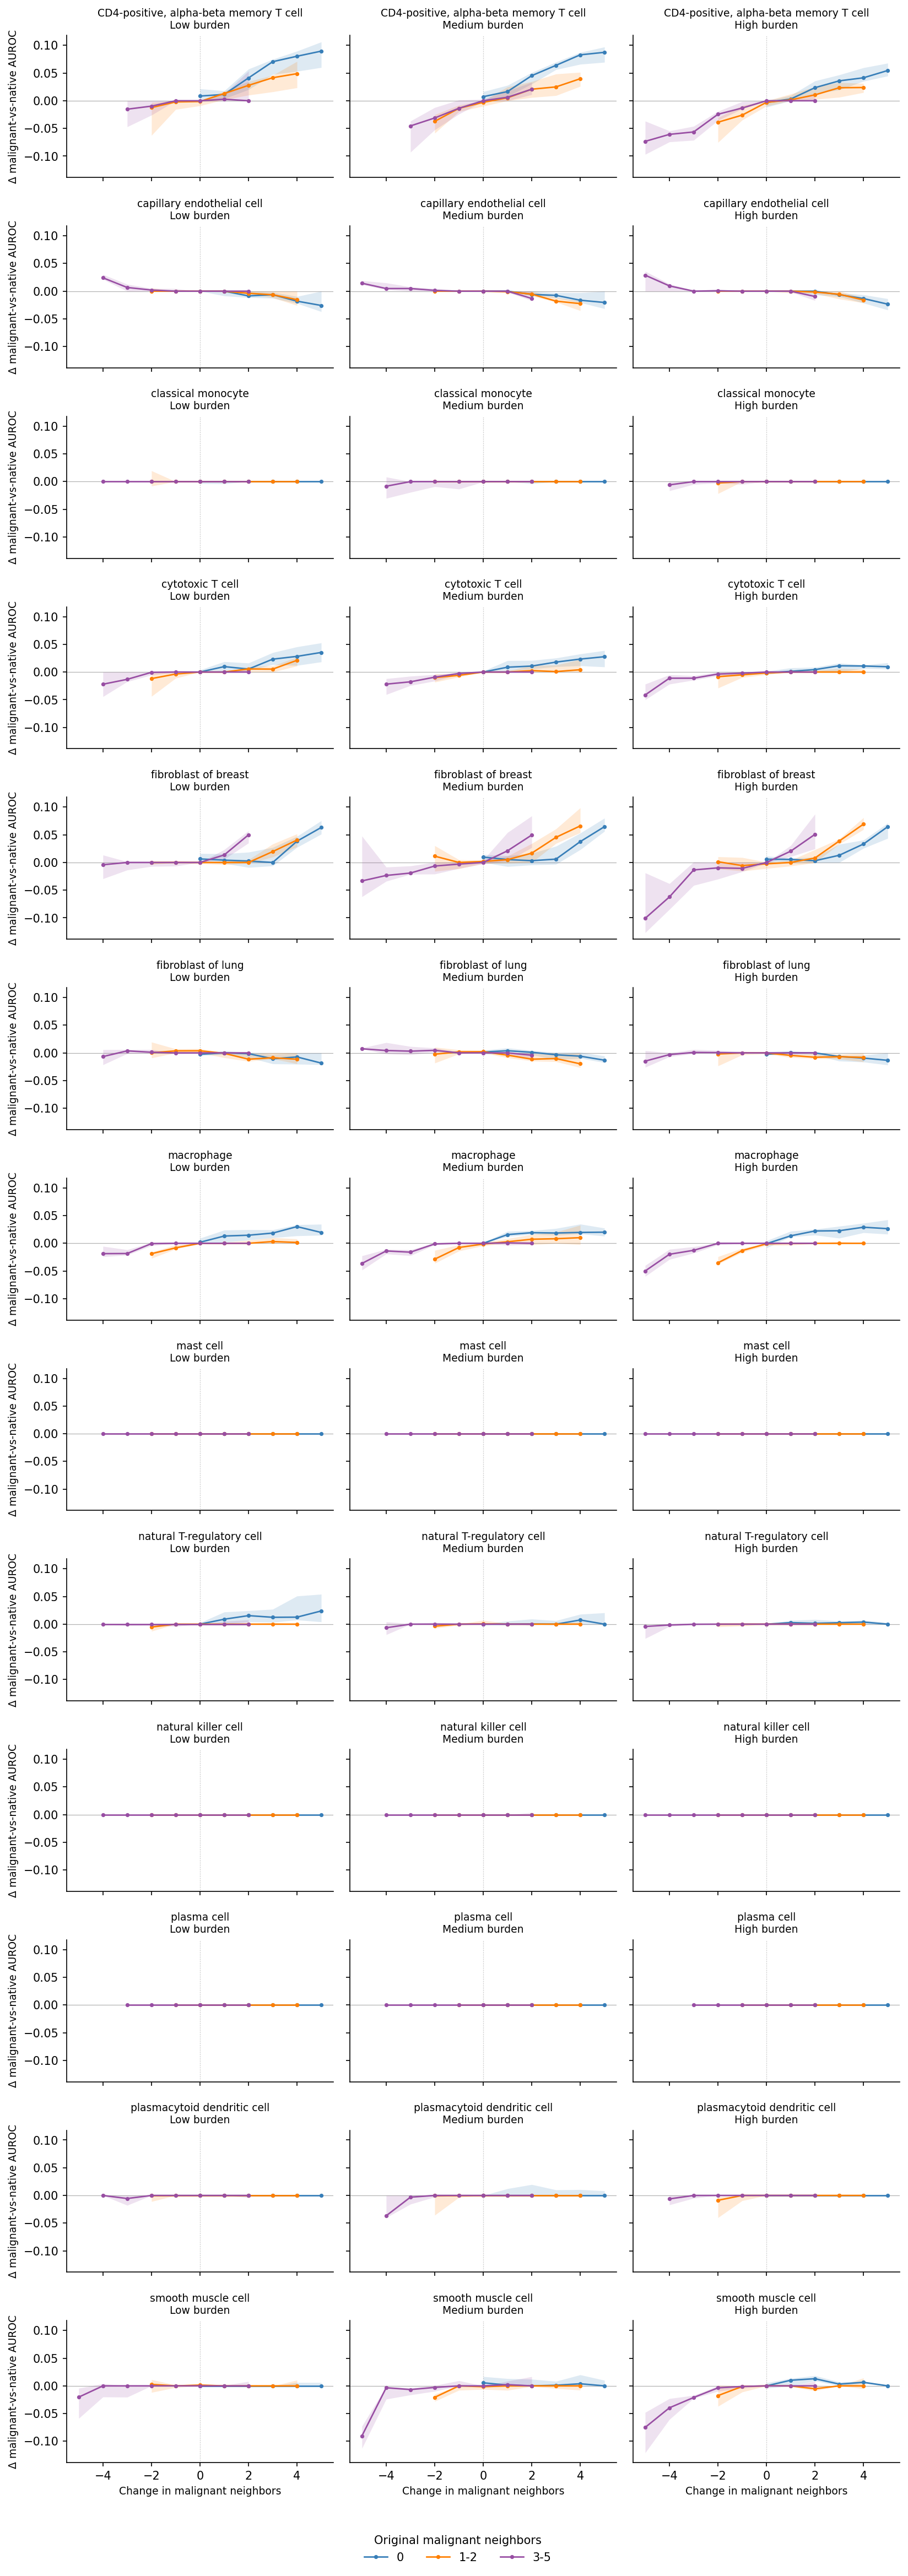

Saved grid for 13 cell types to /home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220/burden_stratified_context_auroc_response


In [8]:
# One cell type per row; the three burden quantiles share axes across the grid.
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

BURDEN_GRID_QUERY_TYPES = None  # All types, or an ordered list of exact cell-type labels.
BURDEN_GRID_MIN_QUERIES = 5
BURDEN_GRID_MIN_SECTIONS = 3
burden_grid_run = Path("/home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220")
import sys
if str(burden_grid_run) not in sys.path:
    sys.path.insert(0, str(burden_grid_run))
from marker_auroc_responses import compute_marker_auroc_responses
compute_marker_auroc_responses(burden_grid_run)
burden_grid_out = burden_grid_run / "burden_stratified_context_auroc_response"
# Read the full responses so this grid is independent of the pooled plot's type filter.
burden_grid_rows = pd.read_csv(burden_grid_run / "marker_auroc_context_responses" / "marker_auroc_context_responses.csv.gz")
burden_grid_rows = burden_grid_rows.loc[
    burden_grid_rows.context_selected_for_shared_panel.eq(True)
    & burden_grid_rows.context_kind.ne("unchanged_control")
    & burden_grid_rows.query_burden_quantile.isin(["low", "medium", "high"])
    & np.isfinite(burden_grid_rows.delta_marker_auroc)
].copy()
burden_grid_rows["delta_malignant_neighbors"] = (
    burden_grid_rows.context_malignant_token_count - burden_grid_rows.query_malignant_token_count
).astype(int)
burden_grid_types = sorted(burden_grid_rows.query_cell_type.unique()) if BURDEN_GRID_QUERY_TYPES is None else list(BURDEN_GRID_QUERY_TYPES)
missing_types = set(burden_grid_types) - set(burden_grid_rows.query_cell_type)
if missing_types or not burden_grid_types:
    raise ValueError(f"Empty selection or unavailable cell types: {missing_types}")
burden_grid_keys = ["slice", "query_cell_type", "query_burden_quantile", "query_neighbor_level", "delta_malignant_neighbors"]
burden_grid_queries = burden_grid_rows.groupby(burden_grid_keys + ["query_cell_id"], observed=True).delta_marker_auroc.mean().reset_index()
burden_grid_sections = burden_grid_queries.groupby(burden_grid_keys, observed=True).agg(
    delta_marker_auroc=("delta_marker_auroc", "median"), n_queries=("query_cell_id", "nunique")
).reset_index()
burden_grid_summary = burden_grid_sections.loc[burden_grid_sections.n_queries.ge(BURDEN_GRID_MIN_QUERIES)].groupby(
    burden_grid_keys[1:], observed=True
).agg(median=("delta_marker_auroc", "median"),
      q25=("delta_marker_auroc", lambda s: s.quantile(.25)),
      q75=("delta_marker_auroc", lambda s: s.quantile(.75)),
      n_sections=("slice", "nunique")).reset_index()
burden_grid_out.mkdir(exist_ok=True)
burden_grid_sections.to_csv(burden_grid_out / "cell_type_grid_section_responses.csv.gz", index=False, compression="gzip")
burden_grid_summary.to_csv(burden_grid_out / "cell_type_grid_summary.csv", index=False)
fig, axes = plt.subplots(len(burden_grid_types), 3, figsize=(11, 2.4 * len(burden_grid_types)),
                         sharex=True, sharey=True, squeeze=False, dpi=150)
burden_grid_colors = {"0": "#377eb8", "1-2": "#ff7f00", "3-5": "#984ea3"}
for row, query_type in enumerate(burden_grid_types):
    for col, quantile in enumerate(["low", "medium", "high"]):
        ax = axes[row, col]
        for group, color in burden_grid_colors.items():
            current = burden_grid_summary.loc[
                burden_grid_summary.query_cell_type.eq(query_type)
                & burden_grid_summary.query_burden_quantile.eq(quantile)
                & burden_grid_summary.query_neighbor_level.eq(group)
            ].set_index("delta_malignant_neighbors").reindex(range(-5, 6))
            current.loc[current.n_sections.fillna(0).lt(BURDEN_GRID_MIN_SECTIONS), ["median", "q25", "q75"]] = np.nan
            ax.plot(current.index, current["median"], color=color, marker="o", ms=2.5, lw=1.3, label=group)
            ax.fill_between(current.index.to_numpy(), current.q25.to_numpy(float), current.q75.to_numpy(float), color=color, alpha=.16, linewidth=0)
        ax.axhline(0, color=".7", lw=.6, zorder=0)
        ax.axvline(0, color=".7", lw=.6, ls=":", zorder=0)
        ax.set_title(f"{query_type}\n{quantile.capitalize()} burden", fontsize=9)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
        ax.spines[["top", "right"]].set_visible(False)
        if col == 0:
            ax.set_ylabel("Δ malignant-vs-native AUROC", fontsize=9)
        if row == len(burden_grid_types) - 1:
            ax.set_xlabel("Change in malignant neighbors", fontsize=9)
fig.legend(*axes[0, 0].get_legend_handles_labels(), title="Original malignant neighbors", loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(.5, 0))
fig.tight_layout(rect=[0, .025, 1, 1], h_pad=1.5)
for suffix in ["png", "pdf"]:
    fig.savefig(burden_grid_out / f"cell_type_burden_quantile_delta_marker_auroc.{suffix}", bbox_inches="tight")
plt.show()
print(f"Saved grid for {len(burden_grid_types)} cell types to {burden_grid_out}")


## Gene-specific response relative to native markers: nine-stratum heatmap

For each expressed malignant-panel gene g, W is the **strict fraction of that query type’s expressed native markers** scored below g; ties count as zero wins, matching the gene-wise formula. The native comparison set is held fixed across swaps. ΔW subtracts that query’s original W. This differs from AUROC only in tie treatment and the fact that it is gene-specific rather than averaged over positive genes.

Within each section × superclass × burden × original-context group, calculate Spearman(Δ encoded malignant count, ΔW), requiring ≥10 expressing queries, ≥3 distinct Δcount values, and nonconstant ΔW. Pool exact types’ pairs only within each shared stratum, each using its own native marker set. The main color is the **equal-unit median over valid section × burden × original-group correlations**, not a correlation of pooled strata. Require ≥3 supported sections per displayed gene/superclass. Save all 72 possible units with exclusion reasons. Text indicates section-median sign agreement, not significance; the coverage heatmap reports supported units/72.

Landscape gene order uses hierarchical clustering of the signed superclass response profiles. No naive pair-level p-values are calculated: swaps within query are dependent. Family differences can reflect their different native marker sets as well as model responses.


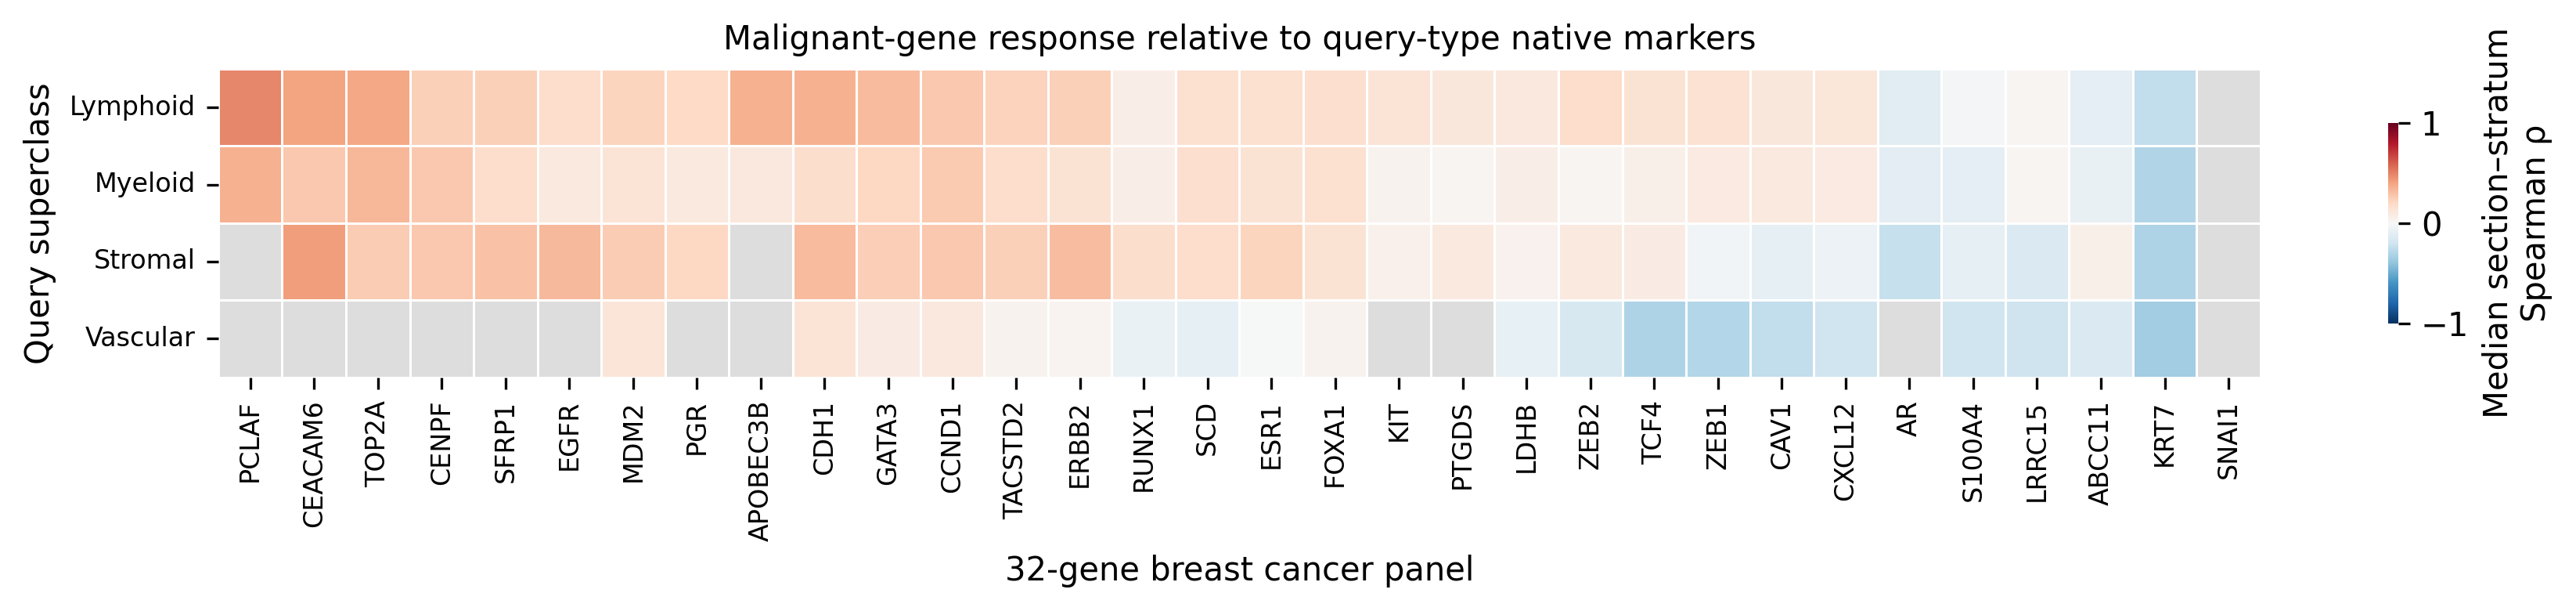

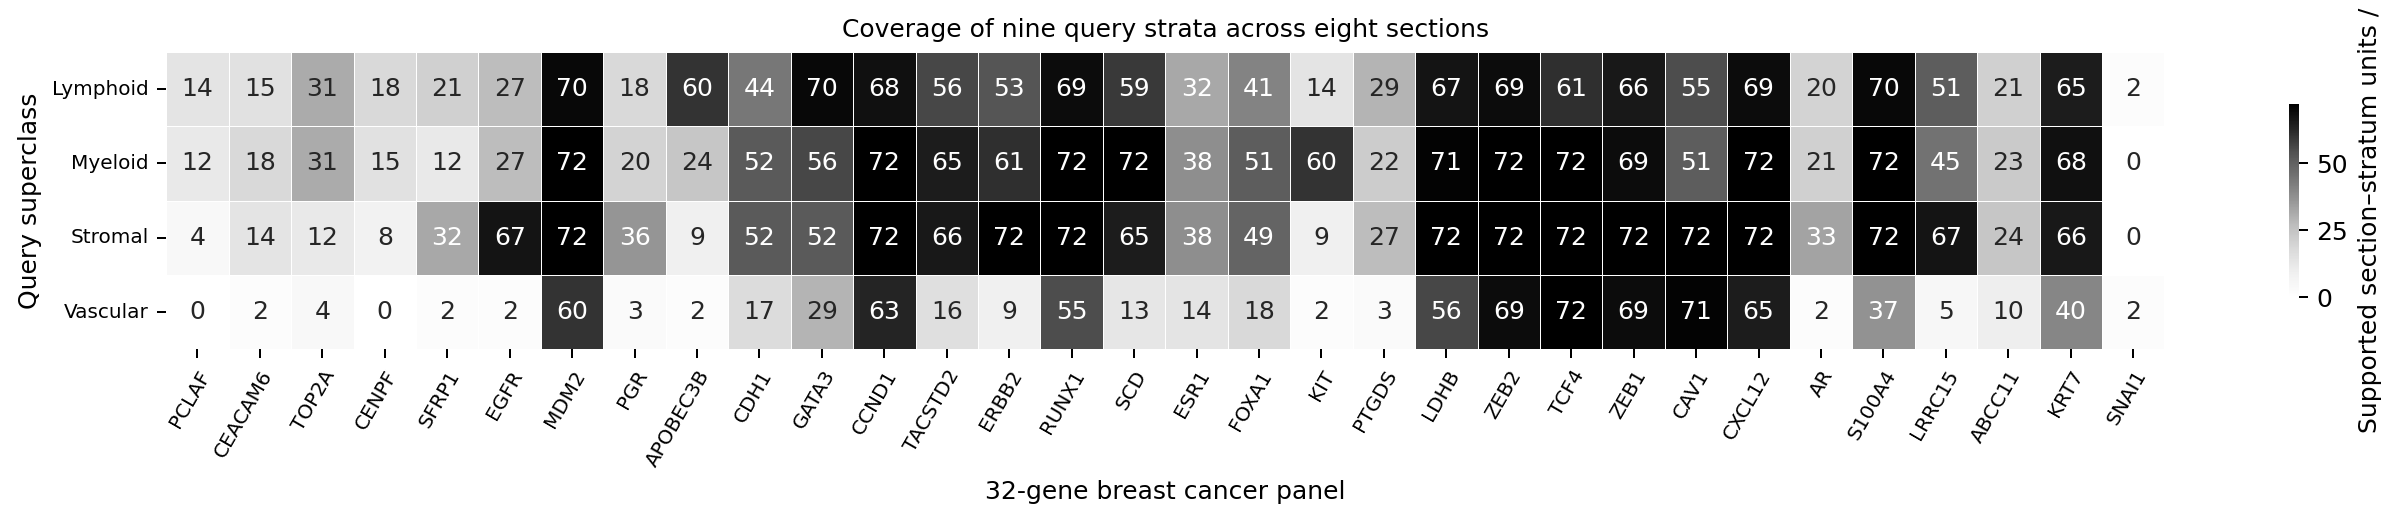

Saved heatmaps and section-level support tables: /home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220/gene_native_win_stratified_context_correlations


In [35]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

GENE_WIN_RUN = Path("/home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220")
if str(GENE_WIN_RUN) not in sys.path:
    sys.path.insert(0, str(GENE_WIN_RUN))
from gene_native_win_context_correlations import compute_stratified_gene_win_correlations
GENE_WIN_MIN_QUERIES = 10
GENE_WIN_MIN_SECTIONS = 3
GENE_WIN_MIN_DELTA_LEVELS = 3
GENE_WIN_CLUSTER_ROWS = True  # Group similar signed superclass response profiles.
GENE_WIN_ANNOTATE = False  # k/n sections agreeing with the median sign, not significance.
GENE_WIN_FAMILY_ORDER = ["Lymphoid", "Myeloid", "Stromal", "Vascular"]
GENE_WIN_TYPE_ORDER = None  # Optional ordered subset of exact cell-type names.
gene_win_out = compute_stratified_gene_win_correlations(
    GENE_WIN_RUN, min_queries=GENE_WIN_MIN_QUERIES, min_delta_levels=GENE_WIN_MIN_DELTA_LEVELS)
gene_win_summary = pd.read_csv(gene_win_out / "gene_win_correlation_summary.csv")
gene_win_markers = json.loads((GENE_WIN_RUN / "design.json").read_text())["marker_genes"]
for kind, title in [("family", "Query superclass")]:
    current = gene_win_summary.loc[gene_win_summary.group_kind.eq(kind)]
    columns = GENE_WIN_FAMILY_ORDER if kind == "family" else (
        sorted(current.query_group.unique()) if GENE_WIN_TYPE_ORDER is None else GENE_WIN_TYPE_ORDER)
    values = current.pivot(index="gene", columns="query_group", values="median_rho").reindex(index=gene_win_markers, columns=columns)
    support = current.pivot(index="gene", columns="query_group", values="n_sections").reindex_like(values)
    agreement = current.pivot(index="gene", columns="query_group", values="n_same_sign").reindex_like(values)
    values = values.mask(support.lt(GENE_WIN_MIN_SECTIONS))
    if GENE_WIN_CLUSTER_ROWS:
        from scipy.cluster.hierarchy import linkage, leaves_list
        supported_genes = values.index[values.notna().any(axis=1)].tolist()
        missing_genes = values.index[values.isna().all(axis=1)].tolist()
        cluster_values = values.loc[supported_genes].copy()
        # Impute missing entries with that gene's mean only for clustering;
        # the displayed heatmap and saved response matrix retain missing values.
        cluster_values = cluster_values.T.fillna(cluster_values.mean(axis=1)).T
        if len(supported_genes) > 1:
            tree = linkage(cluster_values.to_numpy(), method="average", metric="euclidean", optimal_ordering=True)
            ordered_genes = cluster_values.index[leaves_list(tree)].tolist()
            # Flip the complete dendrogram orientation to place the more positive end first.
            if values.loc[ordered_genes[0]].mean() < values.loc[ordered_genes[-1]].mean():
                ordered_genes.reverse()
        else:
            ordered_genes = supported_genes
        ordered_genes += missing_genes
        values = values.reindex(ordered_genes)
        support = support.reindex(ordered_genes)
        agreement = agreement.reindex(ordered_genes)
    pd.DataFrame({"gene": values.index, "row": np.arange(1, len(values) + 1)}).to_csv(
        gene_win_out / f"gene_native_win_delta_context_{kind}_row_order.csv", index=False)
    labels = pd.DataFrame("", index=values.index, columns=values.columns)
    for gene in values.index:
        for group in values.columns:
            if np.isfinite(values.loc[gene, group]):
                labels.loc[gene, group] = f"{int(agreement.loc[gene, group])}/{int(support.loc[gene, group])}"
    fig, ax = plt.subplots(figsize=(12, 2.7), dpi=300)
    ax.set_facecolor("#dddddd")
    sns.heatmap(values.T, ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                annot=labels.T if GENE_WIN_ANNOTATE else False, fmt="", annot_kws={"fontsize":7},
                linewidths=.35, linecolor="white",
                cbar_kws={"label":"Median section–stratum\nSpearman ρ", "shrink":.65})
    ax.set_title("Malignant-gene response relative to query-type native markers", fontsize=10)
    ax.set_xlabel("32-gene breast cancer panel")
    ax.set_ylabel(title)
    ax.tick_params(axis="y", labelrotation=0, labelsize=8)
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    for label in ax.get_xticklabels():
        label.set_rotation_mode("anchor")
        label.set_ha("right")
        label.set_va("center")
    fig.tight_layout()
    for suffix in ["png", "pdf"]:
        fig.savefig(gene_win_out / f"gene_native_win_delta_context_{kind}_heatmap.{suffix}", bbox_inches="tight")
    values.to_csv(gene_win_out / f"gene_native_win_delta_context_{kind}_heatmap.csv")
    plt.show()
coverage = current.pivot(index="gene", columns="query_group", values="n_section_stratum_units").reindex(index=values.index, columns=values.columns)
fig, ax = plt.subplots(figsize=(15, 3.), dpi=180)
sns.heatmap(coverage.T, cmap="Greys", vmin=0, vmax=72, annot=True, fmt=".0f", linewidths=.35,
            cbar_kws={"label":"Supported section–stratum units / 72", "shrink":.65}, ax=ax)
ax.set_title("Coverage of nine query strata across eight sections", fontsize=10)
ax.set_xlabel("32-gene breast cancer panel")
ax.set_ylabel("Query superclass")
ax.tick_params(axis="y", labelrotation=0, labelsize=8)
ax.tick_params(axis="x", labelrotation=60, labelsize=8)
for label in ax.get_xticklabels():
    label.set_rotation_mode("anchor")
    label.set_ha("right")
fig.tight_layout()
for suffix in ["png", "pdf"]:
    fig.savefig(gene_win_out / f"gene_native_win_stratified_coverage.{suffix}", bbox_inches="tight")
plt.show()
print("Saved heatmaps and section-level support tables:", gene_win_out)


## Controlled versus native AUROC slopes, adjusting by exact query type

Within section × exact query type × burden, fit native weighted OLS with an intercept: original matched-marker AUROC versus original malignant count. The controlled coefficient averages within-query OLS slopes of ΔAUROC versus Δ malignant count for **the same queries**. Give available original-neighbor groups equal total weight and their queries equal weights, requiring ≥5 queries/group and ≥3 context levels for each query’s controlled slope. A type-level native fit needs ≥10 queries and ≥3 original count levels.

Average paired-valid exact-type coefficients equally within superclass/section, then report section medians/IQR in the scatter. Faint points are sections; the diagonal is equal slopes. Native association conditions on section, annotation and burden tertile, but remains observational and does not adjust every aspect of query state. Changes relative to the earlier scatter also reflect the new denominator and the surviving query cohort; this is not a pure intervention on marker scores.


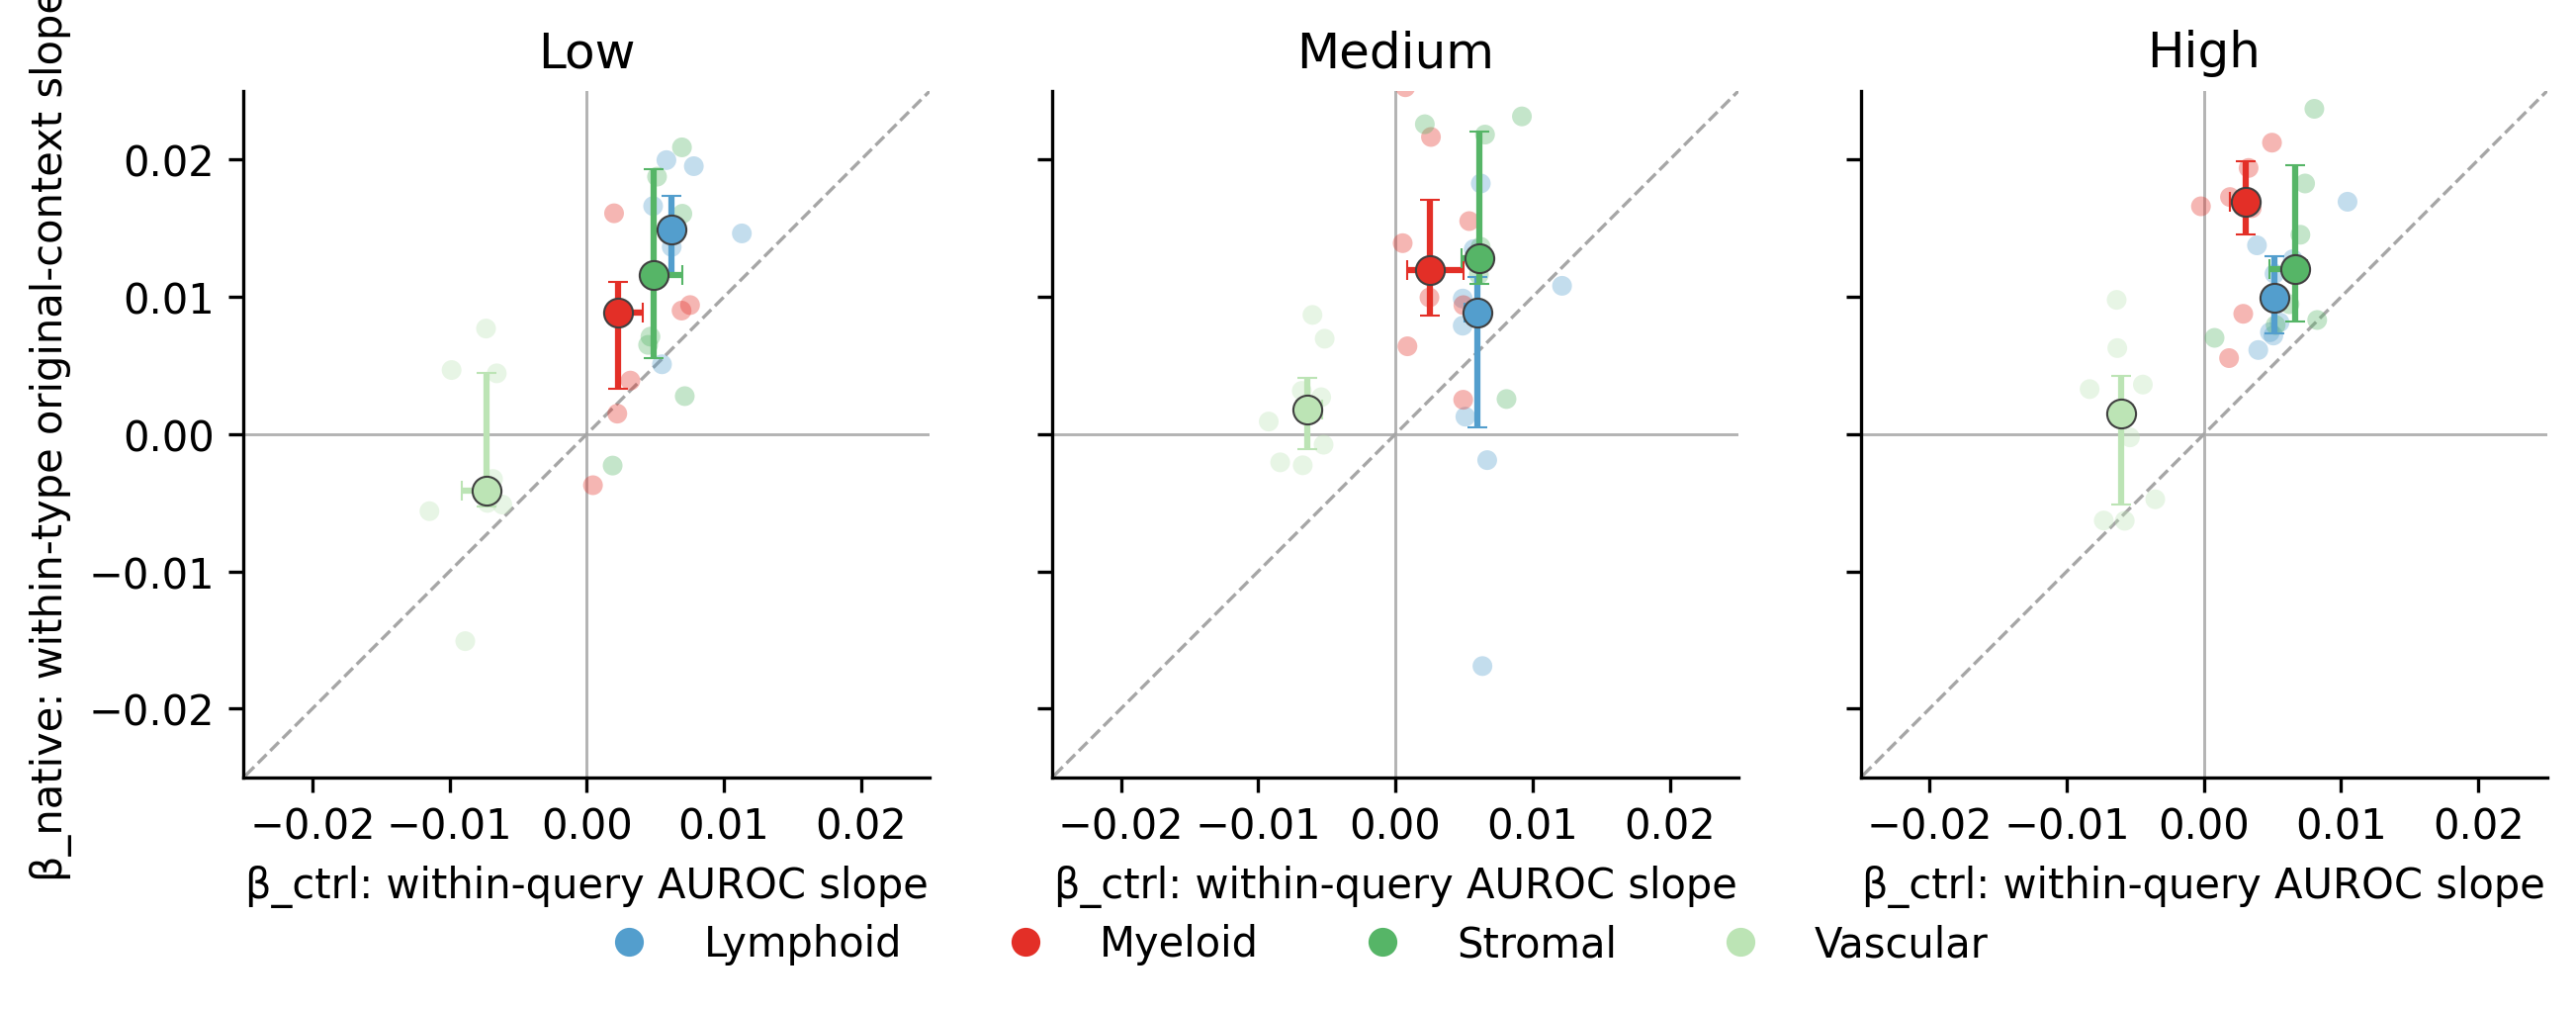

,query_family,query_burden_quantile,beta_ctrl,beta_native,n_sections
0,Lymphoid,high,0.005104,0.009918,8
1,Lymphoid,low,0.006201,0.014882,8
2,Lymphoid,medium,0.005973,0.008894,8
3,Myeloid,high,0.003031,0.016942,8
4,Myeloid,low,0.002298,0.008863,8
5,Myeloid,medium,0.002542,0.011940,8
6,Stromal,high,0.006635,0.012001,8
7,Stromal,low,0.004885,0.011585,8
8,Stromal,medium,0.006155,0.012816,8
9,Vascular,high,-0.006042,0.001526,8


Slopes are AUROC change per additional malignant neighbor. Saved: /home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220/auroc_control_native_within_type


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

CONTROL_NATIVE_RUN = Path("/home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220")
CONTROL_NATIVE_MIN_SECTIONS = 3
CONTROL_NATIVE_FAMILY_ORDER = ["Lymphoid", "Myeloid", "Stromal", "Vascular"]
if str(CONTROL_NATIVE_RUN) not in sys.path:
    sys.path.insert(0, str(CONTROL_NATIVE_RUN))
from auroc_control_native_within_type import compute_control_native_within_type
control_native_out = compute_control_native_within_type(CONTROL_NATIVE_RUN)
control_native_sections = pd.read_csv(control_native_out / "section_control_native_slopes.csv")
control_native_summary = pd.read_csv(control_native_out / "control_native_summary.csv")
control_native_colors = json.loads((CONTROL_NATIVE_RUN / "burden_stratified_context_auroc_response" / "combined_family_colors.json").read_text())["colors"]
control_native_valid = control_native_sections.loc[
    control_native_sections.status.eq("valid")
    & np.isfinite(control_native_sections.beta_ctrl)
    & np.isfinite(control_native_sections.beta_native)]
control_native_xy = control_native_valid[["beta_ctrl", "beta_native"]].to_numpy()
if not control_native_xy.size:
    raise ValueError("No paired controlled/native slopes with adequate support")
control_native_lim = max(np.abs(control_native_xy).max() * 1.12, .005)
fig, axes = plt.subplots(1, 3, figsize=(9, 3), sharex=True, dpi=300,sharey=True)
for ax, burden in zip(axes, ["low", "medium", "high"]):
    ax.axhline(0, color=".7", lw=.7, zorder=0)
    ax.axvline(0, color=".7", lw=.7, zorder=0)
    ax.plot([-control_native_lim, control_native_lim], [-control_native_lim, control_native_lim],
            color=".65", ls="--", lw=.8, zorder=0)
    for family in CONTROL_NATIVE_FAMILY_ORDER:
        color = control_native_colors[family]
        points = control_native_valid.loc[control_native_valid.query_family.eq(family)
            & control_native_valid.query_burden_quantile.eq(burden)]
        ax.scatter(points.beta_ctrl, points.beta_native, color=color, s=23, alpha=.35,
                   edgecolor="none", zorder=2)
        rows = control_native_summary.loc[control_native_summary.query_family.eq(family)
            & control_native_summary.query_burden_quantile.eq(burden)
            & control_native_summary.n_sections.ge(CONTROL_NATIVE_MIN_SECTIONS)]
        for row in rows.itertuples():
            ax.errorbar(row.beta_ctrl, row.beta_native,
                xerr=[[row.beta_ctrl - row.beta_ctrl_q25], [row.beta_ctrl_q75 - row.beta_ctrl]],
                yerr=[[row.beta_native - row.beta_native_q25], [row.beta_native_q75 - row.beta_native]],
                fmt="o", ms=7, color=color, markeredgecolor=".25", markeredgewidth=.5,
                elinewidth=1.5, capsize=2.5, zorder=3)
    ax.set_title(f"{burden.capitalize()}")
    ax.set_xlabel("β_ctrl: within-query AUROC slope")
    # ax.set_xlim(-control_native_lim, control_native_lim)
    # ax.set_ylim(-control_native_lim, control_native_lim)
    ax.set_xlim(-0.025,0.025)
    ax.set_ylim(-0.025,0.025)
    # ax.set_yscale('symlog')
    # ax.set_xscale('symlog')
    ax.set_aspect("equal", adjustable="box")
    ax.spines[["top", "right"]].set_visible(False)
    # ax.ticklabel_format(style="sci", axis="both", scilimits=(-2, 2))
axes[0].set_ylabel("β_native: within-type original-context slope")
fig.tight_layout()
handles = [Line2D([0], [0], marker="o", linestyle="", color=control_native_colors[f], label=f) for f in CONTROL_NATIVE_FAMILY_ORDER]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(.5, -.1))
# fig.tight_layout(rect=[0, .12, 1, 1])

for suffix in ["png", "pdf"]:
    fig.savefig(control_native_out / f"beta_controlled_vs_native.{suffix}", bbox_inches="tight")
plt.show()
display(control_native_summary[["query_family", "query_burden_quantile", "beta_ctrl", "beta_native", "n_sections"]])
print("Slopes are AUROC change per additional malignant neighbor. Saved:", control_native_out)


## Vascular response investigation: malignant-panel genes in capillary endothelial queries

This section follows the proposed five-part diagnosis. It uses the saved 300-query Xenium predictions and the `breast_cancer_chromium_genesubset.h5ad` scRNA-seq reference for expression prevalence and source-opportunity analyses. Gene response is the strict fraction of the query’s expressed endothelial native markers scored below each expressed malignant-panel gene, with ties counting as zero; the native set and eligibility are held fixed across contexts. A gene’s slope is the within-query OLS slope of that score against the change in malignant token count. Query-level slopes are summarized across slices, with bootstrap intervals over queries.

The synthetic prediction files contain final probabilities and context compositions, but not transcript-level sampled source-cell identities. Therefore an exact \(P(source type=t\mid gene labeled admixed)\) cannot be recovered from these files. The source section below reports a clearly labeled scRNA expression-contribution proxy, not that probability. The one-token swap likewise requires new inference; the notebook records the fixed intervention design and creates its matched input panel, while the model rerun should use the saved checkpoint and standard inference entry point. Spatial colocalization is an observational support check, not a causal explanation.


In [ ]:
# Step 1. Per-gene response slopes for capillary endothelial queries.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import anndata as ad
from scipy import sparse
from scipy.stats import linregress

VASC_RUN = RUN
VASC_SOURCE = SOURCE_RUN
VASC_TYPE = "capillary endothelial cell"
VASC_NATIVE = json.loads((VASC_RUN / "query_native_marker_sets.json").read_text())[VASC_TYPE]
VASC_MARKERS = json.loads((VASC_RUN / "design.json").read_text())["marker_genes"]

def _dense_row(x, i):
    z = x[i]
    return z.toarray().ravel() if sparse.issparse(z) else np.asarray(z).ravel()

slope_records = []
for entry in json.loads((VASC_RUN / "design.json").read_text())["slices"]:
    a = ad.read_h5ad(entry["predictions"])
    obs = a.obs.reset_index(drop=True)
    names = a.var.get("feature_name", pd.Series(a.var_names, index=a.var_names)).fillna("").astype(str).to_numpy()
    names = np.where(names == "", a.var_names.astype(str), names)
    gene_idx = {g:i for i,g in enumerate(names)}
    marker_cols = {g:gene_idx[g] for g in VASC_MARKERS if g in gene_idx}
    native_cols = [gene_idx[g] for g in VASC_NATIVE if g in gene_idx]
    probs = a.layers["admix_probs"]
    if sparse.issparse(probs): probs = probs.toarray()
    raw = a.X
    for q, rows in obs.loc[obs.query_cell_type.eq(VASC_TYPE)].groupby("focal_cell_id", sort=False).groups.items():
        rows = np.asarray(list(rows), dtype=int)
        base = rows[obs.loc[rows, "context_kind"].eq("original").to_numpy()]
        if len(base) != 1: continue
        b = int(base[0]); expressed_native = [j for j in native_cols if _dense_row(raw,b)[j] > 0]
        if not expressed_native: continue
        x = (obs.loc[rows,"context_malignant_token_count"].to_numpy(dtype=float) - float(obs.loc[b,"query_malignant_token_count"]))
        keep = obs.loc[rows,"context_kind"].eq("representative").to_numpy()
        rows, x = rows[keep], x[keep]
        if len(np.unique(x)) < 3: continue
        for gene,j in marker_cols.items():
            if _dense_row(raw,b)[j] <= 0: continue
            wins = (probs[rows,j,None] > probs[rows[:,None],np.asarray(expressed_native)[None,:]]).mean(axis=1)
            beta = linregress(x, wins).slope
            slope_records.append(dict(slice=entry["slice"], slice_label=entry["label"], query_cell_id=q, gene=gene, beta_rank_per_malignant_token=beta, n_contexts=len(rows), n_delta_levels=len(np.unique(x))))
    print(entry["label"], "capillary queries with slopes:", len({r['query_cell_id'] for r in slope_records if r['slice']==entry['slice']}))
    del a, probs, raw

vascular_gene_slopes = pd.DataFrame(slope_records)
vascular_gene_slopes.to_csv(VASC_RUN / "vascular_gene_query_slopes.csv.gz", index=False, compression="gzip")
# Bootstrap query-level slopes, stratifying by slice so large sections do not dominate.
rng = np.random.default_rng(741)
summary=[]
for gene, part in vascular_gene_slopes.groupby("gene"):
    per_slice = [g.beta_rank_per_malignant_token.to_numpy() for _,g in part.groupby("slice") if len(g)]
    if not per_slice:
        summary.append(dict(gene=gene,beta=np.nan,ci_low=np.nan,ci_high=np.nan,n_queries=0,n_slices=0,response_class="unassessed"))
        continue
    observed = float(np.median(np.concatenate(per_slice)))
    boots=[]
    for _ in range(2000):
        sampled=np.concatenate([v[rng.integers(0,len(v),len(v))] for v in per_slice])
        boots.append(np.median(sampled))
    lo,hi=np.quantile(boots,[.025,.975])
    summary.append(dict(gene=gene,beta=observed,ci_low=lo,ci_high=hi,n_queries=sum(map(len,per_slice)),n_slices=len(per_slice),
                        response_class="negative" if hi<0 else "positive" if lo>0 else "neutral"))
vascular_gene_summary=pd.DataFrame(summary).sort_values("beta")
vascular_gene_summary.to_csv(VASC_RUN / "vascular_gene_slope_summary.csv",index=False)
display(vascular_gene_summary)
fig,ax=plt.subplots(figsize=(9,8)); y=np.arange(len(vascular_gene_summary))
ax.errorbar(vascular_gene_summary.beta,y,xerr=[vascular_gene_summary.beta-vascular_gene_summary.ci_low,vascular_gene_summary.ci_high-vascular_gene_summary.beta],fmt='o',color='#315a7d',ecolor='#9aabb8',capsize=2)
ax.axvline(0,color='black',lw=.8); ax.set_yticks(y,vascular_gene_summary.gene); ax.set_xlabel('Change in strict malignant-vs-native rank per additional malignant token'); ax.set_title('Capillary endothelial query gene responses (query bootstrap 95% CI)'); ax.grid(axis='x',alpha=.2); plt.tight_layout()


### Step 2. Are negative responders plausible endothelial genes?

For each malignant-panel gene, report detection prevalence and mean expression in capillary endothelial and malignant cells in the breast scRNA-seq reference. The reference is `/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/interim/single-cell/breast_cancer_chromium_genesubset.h5ad`; the expression layer used is `SoupX` when available, otherwise `X`. The correlation is descriptive and uses the gene-level slopes above.


In [ ]:
VASC_REFERENCE = Path("/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/interim/single-cell/breast_cancer_chromium_genesubset.h5ad")
REF_PATH = VASC_REFERENCE
ref = ad.read_h5ad(REF_PATH)
print("scRNA expression-reference file:", REF_PATH)
(VASC_RUN / "vascular_reference_provenance.txt").write_text(str(REF_PATH) + "\n")
label_col = "cell_type" if "cell_type" in ref.obs else "Harmonised_Level4"
ref_types = ref.obs[label_col].astype(str).to_numpy()
ref_names = ref.var.get("feature_name", pd.Series(ref.var_names,index=ref.var_names)).astype("object").fillna("").astype(str).to_numpy()
ref_names = np.where(ref_names=="",ref.var_names.astype(str),ref_names)
ref_gene_idx = {g:i for i,g in enumerate(ref_names)}
ref_X = ref.layers["SoupX"] if "SoupX" in ref.layers else ref.X
plausibility=[]
for gene in VASC_MARKERS:
    if gene not in ref_gene_idx: continue
    j=ref_gene_idx[gene]
    for typ in [VASC_TYPE,"malignant cell"]:
        ix=np.flatnonzero(ref_types==typ)
        vals=ref_X[ix,j]
        vals=vals.toarray().ravel() if sparse.issparse(vals) else np.asarray(vals).ravel()
        plausibility.append(dict(gene=gene,cell_type=typ,n_cells=len(ix),n_expressing=int((vals>0).sum()),detection_prevalence=float((vals>0).mean()),mean_expression=float(vals.mean())))
vascular_plausibility=pd.DataFrame(plausibility)
wide=vascular_plausibility.pivot(index="gene",columns="cell_type",values=["detection_prevalence","mean_expression","n_cells","n_expressing"])
wide.columns=[f"{m}_{t}" for m,t in wide.columns]; wide=wide.reset_index()
vascular_gene_summary=vascular_gene_summary.merge(wide,on="gene",how="left")
vascular_gene_summary.to_csv(VASC_RUN / "vascular_gene_slope_and_reference_summary.csv",index=False)
display(vascular_gene_summary.sort_values("beta"))
from scipy.stats import spearmanr
rho=spearmanr(vascular_gene_summary["detection_prevalence_capillary endothelial cell"], vascular_gene_summary.beta, nan_policy="omit")
print("Spearman rho(prevalence in capillary EC, response slope):",rho.statistic,"p=",rho.pvalue)
fig,ax=plt.subplots(figsize=(6,5));
for _,r in vascular_gene_summary.iterrows():
    ax.scatter(r.get("detection_prevalence_capillary endothelial cell",np.nan),r.beta,c="#bf5b45" if r.response_class=="negative" else "#477da5",s=28)
    ax.annotate(r.gene,(r.get("detection_prevalence_capillary endothelial cell",np.nan),r.beta),fontsize=7,xytext=(2,2),textcoords="offset points")
ax.axhline(0,color="black",lw=.8); ax.set_xlabel("scRNA detection prevalence in capillary endothelial cells"); ax.set_ylabel("Gene response slope β"); ax.set_title(f"Endothelial plausibility vs context response (ρ={rho.statistic:.2f})"); plt.tight_layout()


### Step 3. Synthetic source-label audit (expression-contribution proxy)

The saved predictions do not store the sampled source cell for each synthetic transcript, and the reference matrix does not contain those realized epoch-level labels. This cell therefore estimates each gene’s *potential source contribution* from summed scRNA counts by cell type, normalized across cell types. Treat it as an expression-based source opportunity proxy; it is not \(P(source type=t\mid gene labeled admixed)\). An exact probability requires rerunning the training sampler while recording source-cell/gene draws.


In [ ]:
source_rows=[]
for gene in VASC_MARKERS:
    if gene not in ref_gene_idx: continue
    j=ref_gene_idx[gene]
    for typ in pd.unique(ref_types):
        ix=np.flatnonzero(ref_types==typ)
        vals=ref_X[ix,j]
        total=float(vals.sum())
        source_rows.append(dict(gene=gene,source_cell_type=typ,source_counts=total,n_cells=len(ix)))
source_proxy=pd.DataFrame(source_rows)
source_proxy["source_count_share"] = source_proxy.source_counts / source_proxy.groupby("gene").source_counts.transform("sum").replace(0,np.nan)
source_proxy.to_csv(VASC_RUN / "vascular_gene_source_expression_proxy.csv",index=False)
proxy_wide=source_proxy.pivot(index="gene",columns="source_cell_type",values="source_count_share").fillna(0)
display(proxy_wide.reindex(vascular_gene_summary.gene).style.format("{:.2f}").background_gradient(cmap="Blues",axis=None))
print("These shares reflect reference expression abundance, not realized synthetic-admixture labels.")


### Step 4. Fixed five-token single-token intervention

For each selected capillary query and each context with exactly five neighbor tokens, hold token ranks 2–5 fixed. Make two variants at rank 1: malignant→capillary endothelial and capillary endothelial→malignant. Store the paired neighborhood lists and composition metadata so the same saved checkpoint can score both variants. The original saved predictions cannot answer this counterfactual because each row’s five tokens were not varied one at a time. Run inference on the generated AnnData with the same checkpoint/configuration used for the saved predictions, then compare gene probabilities on the same query expression. Use `Δz_g = z_g(EC token) - z_g(malignant token)`; positive values mean endothelial identity raises predicted admixture probability relative to malignant identity.

The next cell exports matched intervention inputs; it does not launch a model job. Inference can be run with the existing `Heimdall/scripts/run_admixture_inference.py` entry point and the `--use-precomputed-neighbor` option used for this run.


In [ ]:
# Export paired inputs for a reproducible GPU inference rerun.
# Each copy has the same focal expression and 5-token neighborhood except token rank 1.
intervention_dir=VASC_RUN / "vascular_single_token_intervention_inputs"
intervention_dir.mkdir(exist_ok=True)
intervention_manifest=[]
for entry in json.loads((VASC_RUN / "design.json").read_text())["slices"]:
    a=ad.read_h5ad(entry["contexts"])
    obs=a.obs
    types=obs.get("harmony_cell_type",obs.get("query_cell_type")).astype(str)
    eligible=np.flatnonzero((types.to_numpy()==VASC_TYPE) & (obs.context_kind.astype(str).to_numpy()=="representative"))
    base_lists=a.uns["neighbor_celltype_dict"]
    # Keep up to 50 contexts with a malignant token at fixed rank 1; the paired variant
    # changes only that token to endothelial and back.
    eligible=[row for row in eligible if len(base_lists[str(a.obs_names[row])])==5 and base_lists[str(a.obs_names[row])][0]=="malignant cell"]
    if not eligible: continue
    # One candidate context per query, preserving query diversity in the exported panel.
    eligible=(pd.DataFrame({"row":eligible,"query":obs.iloc[eligible].focal_cell_id.astype(str).to_numpy()})
              .groupby("query",sort=False).first()["row"].astype(int).tolist()[:50])
    base_types=list(a.uns["cell_type_dict"].keys())
    variants=[]; variant_obs=[]; variant_lists=[]; variant_props=[]
    for row in eligible:
        rid=str(a.obs_names[row]); toks=list(base_lists[rid])
        if len(toks)!=5: continue
        for source,target,tag in [("malignant cell",VASC_TYPE,"malignant_to_ec"),(VASC_TYPE,"malignant cell","ec_to_malignant")]:
            changed=toks.copy(); changed[0]=target
            variants.append(row); variant_obs.append(dict(original_row=rid,focal_cell_id=str(obs.iloc[row].get("focal_cell_id",rid)),intervention=tag,swapped_rank=1,from_type=source,to_type=target))
            variant_lists.append(changed)
            variant_props.append({t:changed.count(t)/5 for t in base_types})
    if not variants: continue
    out=a[variants].copy(); out.obs=out.obs.reset_index(drop=True)
    for c in variant_obs: pass
    variant_meta=pd.DataFrame(variant_obs,index=out.obs.index)
    for c in variant_meta: out.obs[c]=variant_meta[c].to_numpy()
    out.uns["neighbor_celltype_dict"]={str(n):ls for n,ls in zip(out.obs_names,variant_lists)}
    out.obsm["neighborhood_proportions"]=pd.DataFrame(variant_props,index=out.obs_names).reindex(columns=base_types,fill_value=0)
    dest=intervention_dir/f"{entry['label']}_capillary_rank1_swap_inputs.h5ad";out.write_h5ad(dest,compression="gzip")
    intervention_manifest.append(dict(slice=entry["slice"],label=entry["label"],input=str(dest),n_rows=out.n_obs,checkpoint=json.loads((VASC_RUN/"design.json").read_text())["checkpoint"],milestone=json.loads((VASC_RUN/"design.json").read_text())["milestone"]))
pd.DataFrame(intervention_manifest).to_csv(intervention_dir/"manifest.csv",index=False)
display(pd.DataFrame(intervention_manifest))


In [ ]:
# Optional: launch the paired inference panels with the same checkpoint, then calculate Δ logit scores.
# Set True only when this notebook is running in the configured Heimdall inference environment.
RUN_VASCULAR_INTERVENTION_INFERENCE = False
import subprocess, sys
from scipy.special import logit
intervention_design=json.loads((VASC_RUN / "design.json").read_text())
intervention_preds=intervention_dir / "predictions"; intervention_preds.mkdir(exist_ok=True)
if RUN_VASCULAR_INTERVENTION_INFERENCE:
    for row in intervention_manifest:
        pred=intervention_preds/f"{row['label']}_capillary_rank1_swap_predictions.h5ad"
        cmd=[sys.executable,"/home/jwinchel/Syndri/Heimdall/scripts/run_admixture_inference.py",
             "--st-data",row["input"],"--reference-data",intervention_design["reference"],
             "--checkpoint-dir",intervention_design["checkpoint"],"--milestone",str(intervention_design["milestone"]),
             "--output-dir",str(intervention_preds),"--prepared-name",f"{row['label']}_capillary_rank1_swap_prepared.h5ad",
             "--output-name",pred.name,"--cell-type-col","harmony_cell_type","--coord-cols","x_centroid,y_centroid",
             "--batch-size","16","--use-precomputed-neighbor","--preserve-split-column",
             "--extra-overrides","fc.args.query_cell_type_col=harmony_cell_type"]
        subprocess.run(cmd,check=True)
else:
    print("Inference not launched. Inputs and manifest are saved at", intervention_dir)

intervention_scores=[]
for row in intervention_manifest:
    pred=intervention_preds/f"{row['label']}_capillary_rank1_swap_predictions.h5ad"
    if not pred.exists(): continue
    out=ad.read_h5ad(pred); o=out.obs.reset_index(drop=True); probs=out.layers["admix_probs"]
    probs=probs.toarray() if sparse.issparse(probs) else np.asarray(probs)
    genes=out.var.get("feature_name",pd.Series(out.var_names,index=out.var_names)).fillna("").astype(str).to_numpy()
    genes=np.where(genes=="",out.var_names.astype(str),genes)
    for q,grp in o.groupby("original_row",sort=False):
        idx=grp.index.to_numpy(); aidx=idx[grp.intervention.eq("malignant_to_ec").to_numpy()]; eidx=idx[grp.intervention.eq("ec_to_malignant").to_numpy()]
        if len(aidx)!=1 or len(eidx)!=1: continue
        pm=np.clip(probs[aidx[0]],1e-6,1-1e-6); pe=np.clip(probs[eidx[0]],1e-6,1-1e-6)
        dz=logit(pe)-logit(pm)
        for gene in VASC_MARKERS:
            if gene in set(genes):
                gj=int(np.flatnonzero(genes==gene)[0]); intervention_scores.append(dict(slice=row["slice"],query_cell_id=grp.iloc[0].focal_cell_id,gene=gene,p_malignant_token=pm[gj],p_endothelial_token=pe[gj],delta_logit_endothelial_minus_malignant=float(dz[gj])))
vascular_intervention_scores=pd.DataFrame(intervention_scores)
if len(vascular_intervention_scores):
    vascular_intervention_scores.to_csv(intervention_dir/"gene_delta_logit_scores.csv.gz",index=False,compression="gzip")
    display(vascular_intervention_scores.groupby("gene").delta_logit_endothelial_minus_malignant.agg(["median","count"]).sort_values("median"))


### Step 5. Spatial colocalization support check

For each slice, calculate the malignant fraction among the five nearest non-self cells using the original spatial coordinates. Compare capillary endothelial queries with other query populations, and save each query’s nearest malignant distance as a companion measure. Distances remain in the coordinate units of the Xenium input (typically microns after upstream preprocessing); confirm `coord_cols` before interpreting absolute distances.


In [ ]:
from sklearn.neighbors import NearestNeighbors
spatial_rows=[]
for entry in json.loads((VASC_RUN / "design.json").read_text())["slices"]:
    a=ad.read_h5ad(entry["input"])
    obs=a.obs
    type_col="harmony_cell_type" if "harmony_cell_type" in obs else "cell_type"
    coord_cols=next((cols for cols in [("x_centroid","y_centroid"),("CenterX_global_px","CenterY_global_px"),("x","y")] if all(c in obs for c in cols)),None)
    if coord_cols is None: print("No spatial coordinates:",entry["label"]); continue
    xy=obs[list(coord_cols)].apply(pd.to_numeric,errors="coerce").to_numpy()
    valid=np.isfinite(xy).all(axis=1); ids=np.flatnonzero(valid)
    labels=obs[type_col].astype(str).to_numpy()[ids]
    nn=NearestNeighbors(n_neighbors=min(6,len(ids))).fit(xy[ids])
    dist,ind=nn.kneighbors(xy[ids])
    # Exclude self by matching local row index; retain nearest five neighbors.
    for local,global_i in enumerate(ids):
        candidates=[j for j in ind[local] if j!=local][:5]
        if not candidates: continue
        neighbor_labels=labels[candidates]
        malignant_dist=dist[local][[j!=local for j in ind[local]]][:5]
        malign_d=malignant_dist[np.flatnonzero(neighbor_labels=="malignant cell")]
        spatial_rows.append(dict(slice=entry["slice"],slice_label=entry["label"],cell_id=str(obs.index[global_i]),query_cell_type=str(obs.iloc[global_i][type_col]),
                                 malignant_fraction_k5=float(np.mean(neighbor_labels=="malignant cell")),nearest_malignant_distance=float(malign_d.min()) if len(malign_d) else np.nan,
                                 n_malignant_neighbors=int(np.sum(neighbor_labels=="malignant cell")),coord_x=xy[global_i,0],coord_y=xy[global_i,1]))
spatial_coloc=pd.DataFrame(spatial_rows)
spatial_coloc.to_csv(VASC_RUN/"vascular_spatial_colocalization_query_level.csv.gz",index=False,compression="gzip")
summary=spatial_coloc.groupby(["slice_label","query_cell_type"],observed=True).agg(n_cells=("cell_id","size"),mean_malignant_fraction_k5=("malignant_fraction_k5","mean"),median_nearest_malignant_distance=("nearest_malignant_distance","median")).reset_index()
display(summary.loc[summary.query_cell_type.eq(VASC_TYPE)])
fig,ax=plt.subplots(figsize=(10,4)); order=summary.query_cell_type.drop_duplicates().tolist()
plotdata=[spatial_coloc.loc[spatial_coloc.query_cell_type.eq(t),"malignant_fraction_k5"].dropna().to_numpy() for t in order]
ax.boxplot(plotdata,labels=order,showfliers=False); ax.set_ylabel("Malignant fraction among 5 nearest cells"); ax.tick_params(axis="x",rotation=75); ax.set_title("Spatial malignant-cell proximity by query cell type"); plt.tight_layout()


### Focused reference and response summary for five genes

The table below focuses on **PCLAF, ZEB1, PTGDS, KIT, and CAV1**. Prevalence is the fraction of cells with nonzero `SoupX` expression (or `X` if that layer is unavailable); mean expression is among expressing cells. Specificity is shown as the capillary endothelial / malignant prevalence ratio, alongside the prevalence difference. The response slope and query-bootstrap interval use the saved capillary endothelial predictions above.

In [ ]:
FOCUS_GENES = ["PCLAF", "ZEB1", "PTGDS", "KIT", "CAV1"]
focus_rows=[]
for gene in FOCUS_GENES:
    if gene not in ref_gene_idx: continue
    j=ref_gene_idx[gene]
    row={"gene":gene}
    for pop in [VASC_TYPE,"malignant cell"]:
        ix=np.flatnonzero(ref_types==pop)
        values=ref_X[ix,j]
        values=values.toarray().ravel() if sparse.issparse(values) else np.asarray(values).ravel()
        expressing=values[values>0]
        row[f"n_{pop}"]=len(ix)
        row[f"prevalence_{pop}"]=float(len(expressing)/len(ix)) if len(ix) else np.nan
        row[f"mean_among_expressing_{pop}"]=float(expressing.mean()) if len(expressing) else np.nan
    focus_rows.append(row)
focus_reference=pd.DataFrame(focus_rows)
focus_slopes=vascular_gene_summary.loc[vascular_gene_summary.gene.isin(FOCUS_GENES),["gene","beta","ci_low","ci_high","n_queries","n_slices"]]
vascular_five_gene_table=focus_slopes.merge(focus_reference,on="gene",how="left")
vascular_five_gene_table["capillary_to_malignant_prevalence_ratio"]=(vascular_five_gene_table[f"prevalence_{VASC_TYPE}"]/vascular_five_gene_table["prevalence_malignant cell"].replace(0,np.nan))
vascular_five_gene_table["prevalence_difference"]=(vascular_five_gene_table[f"prevalence_{VASC_TYPE}"]-vascular_five_gene_table["prevalence_malignant cell"])
vascular_five_gene_table=vascular_five_gene_table.set_index("gene").reindex(FOCUS_GENES).reset_index()
vascular_five_gene_table.to_csv(VASC_RUN/"vascular_five_gene_reference_and_response_summary.csv",index=False)
pretty=vascular_five_gene_table.rename(columns={
    f"prevalence_{VASC_TYPE}":"Capillary EC expressing (%)",
    f"mean_among_expressing_{VASC_TYPE}":"Mean capillary EC expression | expressing",
    "prevalence_malignant cell":"Malignant expressing (%)",
    "mean_among_expressing_malignant cell":"Mean malignant expression | expressing",
    "capillary_to_malignant_prevalence_ratio":"Capillary / malignant prevalence ratio",
    "beta":"Context response slope per malignant token","ci_low":"Slope CI low","ci_high":"Slope CI high",
})
pretty["Capillary EC expressing (%)"]*=100
pretty["Malignant expressing (%)"]*=100
display(pretty[["gene","Capillary EC expressing (%)","Mean capillary EC expression | expressing","Malignant expressing (%)","Mean malignant expression | expressing","Capillary / malignant prevalence ratio","prevalence_difference","Context response slope per malignant token","Slope CI low","Slope CI high","n_queries","n_slices"]].round(4))


### Test endothelial plausibility against response slope across all 32 panel genes

The five-gene examples are descriptive. This panel-wide analysis tests whether endothelial plausibility is associated with the capillary-query context-response slope across all 32 malignant-panel genes. The primary plausibility measure is the difference in reference detection prevalence, \(P(g>0\mid capillary\ EC)-P(g>0\mid malignant)\); a positive value means the gene is more often detected in capillary endothelial cells. The sensitivity measure is the log2 ratio of Jeffreys-smoothed prevalence estimates, \(\log_2[(x_{EC}+0.5)/(n_{EC}+1) \, / \, ((x_M+0.5)/(n_M+1))]\). Positive context slopes indicate a higher gene-vs-native rank as malignant-token count increases; a negative association is the pattern predicted if more endothelial-plausible genes are selectively deprioritized in malignant contexts. A companion plot uses the log2 fold change in mean reference expression (capillary EC / malignant), with a 0.01 expression-unit pseudocount; it uses the same response-slope y-axis.

Report Spearman correlation, a gene-bootstrap interval, and a permutation p-value for each plausibility definition. These are exploratory across the fixed 32-gene panel; gene-level dependence and the small panel limit causal interpretation. The table retains all 32 genes and flags missing response slopes.

The final plot cell is self-contained: it reads the saved prediction design and reference directly, computes missing response/plausibility summaries, and caches them using signatures of the source files. It can be run independently of all other notebook cells.


Loaded cached slope and reference results: /home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220/vascular_plausibility_vs_response_cache/7629cb623b3e0441


,plausibility_measure,n_genes,rho,ci_low,ci_high,permutation_p
0,prevalence difference,32,-0.387810,-0.617059,-0.071167,0.027597
1,smoothed log2 prevalence ratio,32,-0.517293,-0.711232,-0.256265,0.000600
2,log2 mean-expression fold change,32,-0.406308,-0.632863,-0.065127,0.017498


,gene,endothelial_plausibility_prevalence_difference,endothelial_plausibility_log2_ratio,beta,ci_low,ci_high,n_queries,response_status
30,ZEB1,0.345832,4.683378,0.000000,-0.000952,0.000000,1527,available
28,TCF4,0.315872,3.723998,-0.004762,-0.007865,-0.001628,1593,available
3,CAV1,0.214342,5.274400,-0.004286,-0.006857,-0.001143,1593,available
8,CXCL12,0.134011,3.331229,0.000000,0.000000,0.000000,1293,available
31,ZEB2,0.069611,2.567170,0.000000,0.000000,0.000000,1460,available
21,PTGDS,0.045500,3.129941,0.000000,-0.002143,0.000000,212,available
14,KIT,0.043432,1.854241,-0.001143,-0.003810,0.000000,303,available
26,SNAI1,0.015767,2.456677,0.000000,0.000000,0.000000,313,available
16,LDHB,0.006738,1.064647,0.000000,0.000000,0.000000,1316,available
23,S100A4,0.001219,0.154433,0.000000,0.000000,0.000000,818,available


Cached inputs/results: /home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220/vascular_plausibility_vs_response_cache/7629cb623b3e0441


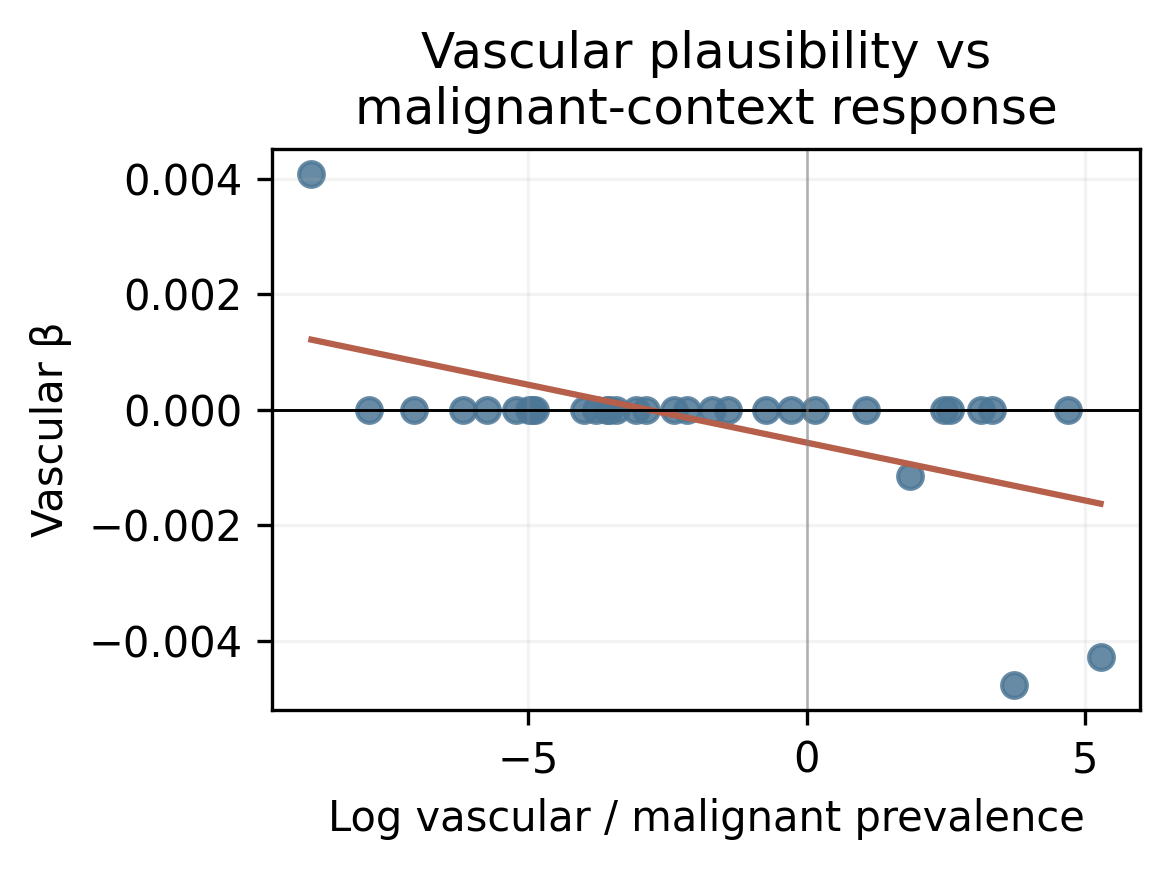

In [31]:
# Standalone vascular plausibility vs malignant-context response plot.
# Reads the saved predictions and reference directly, then reuses a cache keyed
# to those input files. No earlier notebook variables or cells are required.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import anndata as ad
import scipy.sparse as sparse
import matplotlib.pyplot as plt
from scipy.stats import linregress, rankdata, spearmanr

VASC_PLOT_RUN = Path("/home/jwinchel/Syndri/context_analysis/results/query_native_marker_responsiveness_20261020_115220")
VASC_PLOT_REFERENCE = Path("/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/interim/single-cell/breast_cancer_chromium_genesubset.h5ad")
VASC_PLOT_TYPE = "capillary endothelial cell"
VASC_PLOT_CACHE_ROOT = VASC_PLOT_RUN / "vascular_plausibility_vs_response_cache"
VASC_PLOT_DESIGN_PATH = VASC_PLOT_RUN / "design.json"
if not VASC_PLOT_DESIGN_PATH.is_file():
    raise FileNotFoundError(f"Missing saved prediction design: {VASC_PLOT_DESIGN_PATH}")
if not VASC_PLOT_REFERENCE.is_file():
    raise FileNotFoundError(f"Missing scRNA-seq reference: {VASC_PLOT_REFERENCE}")
VASC_PLOT_DESIGN = json.loads(VASC_PLOT_DESIGN_PATH.read_text())
VASC_PLOT_GENES = list(VASC_PLOT_DESIGN["marker_genes"])
VASC_PLOT_SLICES = VASC_PLOT_DESIGN["slices"]
VASC_PLOT_PREDICTION_PATHS = [Path(row["predictions"]) for row in VASC_PLOT_SLICES]
missing_predictions = [str(path) for path in VASC_PLOT_PREDICTION_PATHS if not path.is_file()]
if missing_predictions:
    raise FileNotFoundError("Missing saved predictions:\n" + "\n".join(missing_predictions))

# A changed prediction, reference, or design gets a fresh cache automatically.
VASC_PLOT_INPUTS = [VASC_PLOT_DESIGN_PATH, VASC_PLOT_REFERENCE, *VASC_PLOT_PREDICTION_PATHS]
VASC_PLOT_SIGNATURES = []
for path in VASC_PLOT_INPUTS:
    stat = path.stat()
    VASC_PLOT_SIGNATURES.append({"path": str(path.resolve()), "size": stat.st_size, "mtime_ns": stat.st_mtime_ns})
VASC_PLOT_CACHE_KEY = hashlib.sha256(json.dumps(
    {"version": 2, "inputs": VASC_PLOT_SIGNATURES}, sort_keys=True
).encode()).hexdigest()[:16]
VASC_PLOT_CACHE = VASC_PLOT_CACHE_ROOT / VASC_PLOT_CACHE_KEY
VASC_PLOT_CACHE.mkdir(parents=True, exist_ok=True)
VASC_PLOT_SUMMARY_PATH = VASC_PLOT_CACHE / "gene_plausibility_response.csv"
VASC_PLOT_ASSOC_PATH = VASC_PLOT_CACHE / "association_summary.csv"
VASC_PLOT_QUERY_SLOPES_PATH = VASC_PLOT_CACHE / "gene_query_slopes.csv.gz"
VASC_PLOT_REFERENCE_PATH = VASC_PLOT_CACHE / "reference_plausibility.csv"
VASC_PLOT_EXISTING_SUMMARY = VASC_PLOT_RUN / "vascular_all32_plausibility_vs_response.csv"
VASC_PLOT_EXISTING_ASSOC = VASC_PLOT_RUN / "vascular_all32_plausibility_response_association.csv"
VASC_PLOT_LATEST_INPUT_MTIME = max(item["mtime_ns"] for item in VASC_PLOT_SIGNATURES)

if VASC_PLOT_SUMMARY_PATH.is_file() and VASC_PLOT_ASSOC_PATH.is_file():
    all32 = pd.read_csv(VASC_PLOT_SUMMARY_PATH)
    vascular_all32_association = pd.read_csv(VASC_PLOT_ASSOC_PATH)
    print("Loaded cached slope and reference results:", VASC_PLOT_CACHE)
elif (VASC_PLOT_EXISTING_SUMMARY.is_file() and VASC_PLOT_EXISTING_ASSOC.is_file()
      and VASC_PLOT_EXISTING_SUMMARY.stat().st_mtime_ns >= VASC_PLOT_LATEST_INPUT_MTIME
      and VASC_PLOT_EXISTING_ASSOC.stat().st_mtime_ns >= VASC_PLOT_LATEST_INPUT_MTIME):
    # Reuse the already-computed notebook result when it postdates every input;
    # copy it into this signature-keyed cache for future standalone runs.
    all32 = pd.read_csv(VASC_PLOT_EXISTING_SUMMARY)
    vascular_all32_association = pd.read_csv(VASC_PLOT_EXISTING_ASSOC)
    required = {"gene", "beta", "endothelial_plausibility_log2_ratio", "response_status",
                "mean_expression_capillary endothelial cell", "mean_expression_malignant cell"}
    if not required.issubset(all32.columns) or set(all32.gene) != set(VASC_PLOT_GENES):
        raise ValueError("Existing all-32 summary does not match the current marker panel")
    all32.to_csv(VASC_PLOT_SUMMARY_PATH, index=False)
    vascular_all32_association.to_csv(VASC_PLOT_ASSOC_PATH, index=False)
    (VASC_PLOT_CACHE / "input_signatures.json").write_text(json.dumps({
        "cache_key": VASC_PLOT_CACHE_KEY, "inputs": VASC_PLOT_SIGNATURES,
        "reused_existing_summary": str(VASC_PLOT_EXISTING_SUMMARY),
        "reused_existing_association": str(VASC_PLOT_EXISTING_ASSOC),
    }, indent=2) + "\n")
    print("Copied current precomputed results into the signature-keyed cache:", VASC_PLOT_CACHE)
else:
    # Compute the original per-query slope from saved context predictions.
    slope_records = []
    for entry in VASC_PLOT_SLICES:
        prediction_path = Path(entry["predictions"])
        prediction = ad.read_h5ad(prediction_path)
        obs = prediction.obs.reset_index(drop=True)
        names = prediction.var.get(
            "feature_name", pd.Series(prediction.var_names, index=prediction.var_names)
        ).fillna("").astype(str).to_numpy()
        names = np.where(names == "", prediction.var_names.astype(str), names)
        gene_idx = {gene: i for i, gene in enumerate(names)}
        marker_cols = {gene: gene_idx[gene] for gene in VASC_PLOT_GENES if gene in gene_idx}
        native_genes = json.loads((VASC_PLOT_RUN / "query_native_marker_sets.json").read_text())[VASC_PLOT_TYPE]
        native_cols = [gene_idx[gene] for gene in native_genes if gene in gene_idx]
        probs = prediction.layers["admix_probs"]
        if sparse.issparse(probs):
            probs = probs.toarray()
        raw = prediction.X

        def _vascular_dense_row(matrix, row_index):
            row = matrix[row_index]
            return row.toarray().ravel() if sparse.issparse(row) else np.asarray(row).ravel()

        query_mask = obs.query_cell_type.eq(VASC_PLOT_TYPE)
        for query_id, query_rows in obs.loc[query_mask].groupby("focal_cell_id", sort=False).groups.items():
            query_rows = np.asarray(list(query_rows), dtype=int)
            original_rows = query_rows[obs.loc[query_rows, "context_kind"].eq("original").to_numpy()]
            if len(original_rows) != 1:
                continue
            original_row = int(original_rows[0])
            raw_original = _vascular_dense_row(raw, original_row)
            expressed_native = [col for col in native_cols if raw_original[col] > 0]
            if not expressed_native:
                continue
            delta_malignant = (
                obs.loc[query_rows, "context_malignant_token_count"].to_numpy(dtype=float)
                - float(obs.loc[original_row, "query_malignant_token_count"])
            )
            representative = obs.loc[query_rows, "context_kind"].eq("representative").to_numpy()
            response_rows = query_rows[representative]
            delta_malignant = delta_malignant[representative]
            if len(np.unique(delta_malignant)) < 3:
                continue
            for gene, gene_col in marker_cols.items():
                if raw_original[gene_col] <= 0:
                    continue
                native_probability = probs[np.ix_(response_rows, np.asarray(expressed_native))]
                wins = (probs[response_rows, gene_col, None] > native_probability).mean(axis=1)
                slope = linregress(delta_malignant, wins).slope
                slope_records.append({
                    "slice": entry["slice"], "slice_label": entry["label"],
                    "query_cell_id": query_id, "gene": gene,
                    "beta_rank_per_malignant_token": slope,
                    "n_contexts": len(response_rows),
                    "n_delta_levels": len(np.unique(delta_malignant)),
                })
        del prediction, probs, raw

    gene_query_slopes = pd.DataFrame(slope_records)
    gene_query_slopes.to_csv(VASC_PLOT_QUERY_SLOPES_PATH, index=False, compression="gzip")
    rng = np.random.default_rng(741)
    slope_summary_rows = []
    for gene in VASC_PLOT_GENES:
        part = gene_query_slopes.loc[gene_query_slopes.gene.eq(gene)]
        per_slice = [g.beta_rank_per_malignant_token.to_numpy()
                     for _, g in part.groupby("slice") if len(g)]
        if not per_slice:
            slope_summary_rows.append(dict(gene=gene, beta=np.nan, ci_low=np.nan, ci_high=np.nan,
                n_queries=0, n_slices=0, response_class="unassessed"))
            continue
        beta = float(np.median(np.concatenate(per_slice)))
        bootstraps = []
        for _ in range(2000):
            sampled = np.concatenate([values[rng.integers(0, len(values), len(values))]
                                      for values in per_slice])
            bootstraps.append(np.median(sampled))
        ci_low, ci_high = np.quantile(bootstraps, [0.025, 0.975])
        slope_summary_rows.append(dict(gene=gene, beta=beta, ci_low=ci_low, ci_high=ci_high,
            n_queries=sum(map(len, per_slice)), n_slices=len(per_slice),
            response_class="negative" if ci_high < 0 else "positive" if ci_low > 0 else "neutral"))
    slope_summary = pd.DataFrame(slope_summary_rows)

    # Compute reference prevalence for all panel genes directly from the saved reference.
    reference = ad.read_h5ad(VASC_PLOT_REFERENCE)
    reference_label = "cell_type" if "cell_type" in reference.obs else "Harmonised_Level4"
    reference_types = reference.obs[reference_label].astype(str).to_numpy()
    reference_names = reference.var.get(
        "feature_name", pd.Series(reference.var_names, index=reference.var_names)
    ).astype("object").fillna("").astype(str).to_numpy()
    reference_names = np.where(reference_names == "", reference.var_names.astype(str), reference_names)
    reference_gene_idx = {gene: i for i, gene in enumerate(reference_names)}
    reference_matrix = reference.layers["SoupX"] if "SoupX" in reference.layers else reference.X
    reference_rows = []
    for gene in VASC_PLOT_GENES:
        if gene not in reference_gene_idx:
            continue
        column = reference_gene_idx[gene]
        for cell_type in [VASC_PLOT_TYPE, "malignant cell"]:
            rows = np.flatnonzero(reference_types == cell_type)
            values = reference_matrix[rows, column]
            values = values.toarray().ravel() if sparse.issparse(values) else np.asarray(values).ravel()
            reference_rows.append(dict(gene=gene, cell_type=cell_type, n_cells=len(rows),
                n_expressing=int((values > 0).sum()),
                detection_prevalence=float((values > 0).mean()) if len(values) else np.nan,
                mean_expression=float(values.mean()) if len(values) else np.nan))
    reference_plausibility = pd.DataFrame(reference_rows)
    reference_plausibility.to_csv(VASC_PLOT_REFERENCE_PATH, index=False)
    reference_wide = reference_plausibility.pivot(index="gene", columns="cell_type",
        values=["detection_prevalence", "mean_expression", "n_cells", "n_expressing"])
    reference_wide.columns = [f"{metric}_{cell_type}" for metric, cell_type in reference_wide.columns]
    reference_wide = reference_wide.reset_index()
    all32 = pd.DataFrame({"gene": VASC_PLOT_GENES}).merge(slope_summary, on="gene", how="left", validate="one_to_one")
    all32 = all32.merge(reference_wide, on="gene", how="left", validate="one_to_one")

    prev_ec = f"detection_prevalence_{VASC_PLOT_TYPE}"
    prev_mal = "detection_prevalence_malignant cell"
    n_ec = f"n_cells_{VASC_PLOT_TYPE}"
    n_mal = "n_cells_malignant cell"
    all32["endothelial_plausibility_prevalence_difference"] = all32[prev_ec] - all32[prev_mal]
    p_ec = (all32[f"n_expressing_{VASC_PLOT_TYPE}"] + 0.5) / (all32[n_ec] + 1.0)
    p_mal = (all32["n_expressing_malignant cell"] + 0.5) / (all32[n_mal] + 1.0)
    all32["endothelial_plausibility_log2_ratio"] = np.log2(p_ec / p_mal)
    all32["response_status"] = np.where(np.isfinite(all32.beta), "available", "missing slope")

    def _vascular_panel_spearman(x, y, seed=20261022, n_boot=5000, n_perm=10000):
        keep = np.isfinite(x) & np.isfinite(y)
        x, y = np.asarray(x)[keep], np.asarray(y)[keep]
        n = len(x)
        if n < 4 or np.unique(x).size < 2 or np.unique(y).size < 2:
            return dict(n_genes=n, rho=np.nan, ci_low=np.nan, ci_high=np.nan, permutation_p=np.nan)
        rho = float(spearmanr(x, y).statistic)
        rng = np.random.default_rng(seed)
        boots = []
        for _ in range(n_boot):
            ix = rng.integers(0, n, n)
            if np.unique(x[ix]).size > 1 and np.unique(y[ix]).size > 1:
                boots.append(spearmanr(x[ix], y[ix]).statistic)
        ci_low, ci_high = np.quantile(boots, [0.025, 0.975]) if boots else (np.nan, np.nan)
        rank_x, rank_y = rankdata(x), rankdata(y)
        rank_x, rank_y = rank_x - rank_x.mean(), rank_y - rank_y.mean()
        denom = np.sqrt(np.dot(rank_x, rank_x) * np.dot(rank_y, rank_y))
        observed = np.dot(rank_x, rank_y) / denom
        null = np.empty(n_perm)
        for index in range(n_perm):
            null[index] = np.dot(rank_x, rng.permutation(rank_y)) / denom
        p_value = (1 + np.sum(np.abs(null) >= abs(observed))) / (n_perm + 1)
        return dict(n_genes=n, rho=rho, ci_low=float(ci_low), ci_high=float(ci_high), permutation_p=float(p_value))

    association_rows = []
    for label, xcol in [
        ("prevalence difference", "endothelial_plausibility_prevalence_difference"),
        ("smoothed log2 prevalence ratio", "endothelial_plausibility_log2_ratio"),
    ]:
        association_rows.append(dict(plausibility_measure=label,
            **_vascular_panel_spearman(all32[xcol].to_numpy(), all32.beta.to_numpy())))
    vascular_all32_association = pd.DataFrame(association_rows)

    # Cache the query slopes, reference summary, joined gene table, associations,
    # and exact input signatures so reruns skip the expensive calculations.
    all32.to_csv(VASC_PLOT_SUMMARY_PATH, index=False)
    vascular_all32_association.to_csv(VASC_PLOT_ASSOC_PATH, index=False)
    (VASC_PLOT_CACHE / "input_signatures.json").write_text(json.dumps({
        "cache_key": VASC_PLOT_CACHE_KEY, "inputs": VASC_PLOT_SIGNATURES,
        "reference_layer": "SoupX" if "SoupX" in reference.layers else "X",
        "reference_label": reference_label,
        "prediction_count": len(VASC_PLOT_PREDICTION_PATHS),
    }, indent=2) + "\n")
    print("Computed and cached gene slopes and reference plausibility:", VASC_PLOT_CACHE)

# Add a companion expression-based plausibility measure. Means are computed over all
# cells in each reference population; a small pseudocount keeps zero means finite.
VASC_EXPRESSION_PSEUDOCOUNT = 0.01
VASC_MEAN_EC = f"mean_expression_{VASC_PLOT_TYPE}"
VASC_MEAN_MALIGNANT = "mean_expression_malignant cell"
missing_expression_columns = {VASC_MEAN_EC, VASC_MEAN_MALIGNANT} - set(all32.columns)
if missing_expression_columns:
    raise KeyError(f"Reference mean-expression columns are missing: {sorted(missing_expression_columns)}")
all32["endothelial_expression_log2fc"] = np.log2(
    (all32[VASC_MEAN_EC].clip(lower=0) + VASC_EXPRESSION_PSEUDOCOUNT)
    / (all32[VASC_MEAN_MALIGNANT].clip(lower=0) + VASC_EXPRESSION_PSEUDOCOUNT)
)

def _vascular_expression_association(x, y, seed=20261023, n_boot=5000, n_perm=10000):
    keep = np.isfinite(x) & np.isfinite(y)
    x, y = np.asarray(x)[keep], np.asarray(y)[keep]
    n = len(x)
    if n < 4 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return dict(n_genes=n, rho=np.nan, ci_low=np.nan, ci_high=np.nan, permutation_p=np.nan)
    rho = float(spearmanr(x, y).statistic)
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        ix = rng.integers(0, n, n)
        if np.unique(x[ix]).size > 1 and np.unique(y[ix]).size > 1:
            boots.append(spearmanr(x[ix], y[ix]).statistic)
    ci_low, ci_high = np.quantile(boots, [0.025, 0.975]) if boots else (np.nan, np.nan)
    rank_x, rank_y = rankdata(x), rankdata(y)
    rank_x, rank_y = rank_x - rank_x.mean(), rank_y - rank_y.mean()
    denom = np.sqrt(np.dot(rank_x, rank_x) * np.dot(rank_y, rank_y))
    observed = np.dot(rank_x, rank_y) / denom
    null = np.empty(n_perm)
    for index in range(n_perm):
        null[index] = np.dot(rank_x, rng.permutation(rank_y)) / denom
    p_value = (1 + np.sum(np.abs(null) >= abs(observed))) / (n_perm + 1)
    return dict(n_genes=n, rho=rho, ci_low=float(ci_low), ci_high=float(ci_high), permutation_p=float(p_value))

# Refresh the expression association on every standalone run, while retaining cached prevalence results.
expression_measure = "log2 mean-expression fold change"
vascular_all32_association = vascular_all32_association.loc[
    ~vascular_all32_association.plausibility_measure.eq(expression_measure)
].copy()
expression_row = dict(plausibility_measure=expression_measure, **_vascular_expression_association(
    all32["endothelial_expression_log2fc"].to_numpy(), all32.beta.to_numpy()))
vascular_all32_association = pd.concat(
    [vascular_all32_association, pd.DataFrame([expression_row])], ignore_index=True)
# Persist the derived measure and association in both signature cache and run-level outputs.
all32.to_csv(VASC_PLOT_SUMMARY_PATH, index=False)
vascular_all32_association.to_csv(VASC_PLOT_ASSOC_PATH, index=False)
all32.to_csv(VASC_PLOT_EXISTING_SUMMARY, index=False)
vascular_all32_association.to_csv(VASC_PLOT_EXISTING_ASSOC, index=False)

# Make the plotted measure and gene annotations explicit.
fig, ax = plt.subplots(figsize=(4, 3),dpi=300)
focus_labels = {"PCLAF", "ZEB1", "PTGDS", "KIT", "CAV1", "TCF4"}
plot_x = "endothelial_plausibility_log2_ratio"
valid = all32.loc[np.isfinite(all32[plot_x]) & np.isfinite(all32.beta)]
ax.scatter(valid[plot_x], valid.beta, color="#4d7796", s=35, alpha=0.85)
if len(valid) >= 2:
    slope, intercept = np.polyfit(valid[plot_x], valid.beta, 1)
    x_line = np.linspace(valid[plot_x].min(), valid[plot_x].max(), 100)
    ax.plot(x_line, intercept + slope * x_line, color="#b65f4a", lw=1.5)
# for _, row in valid.loc[valid.gene.isin(focus_labels)].iterrows():
#     ax.annotate(row.gene, (row[plot_x], row.beta), xytext=(3, 3),
#                 textcoords="offset points", fontsize=8)
ax.axhline(0, color="black", lw=0.7)
ax.axvline(0, color="gray", lw=0.6, alpha=0.6)
ax.set_xlabel("Log vascular / malignant prevalence")
ax.set_ylabel("Vascular β")
rho_row = vascular_all32_association.loc[
    vascular_all32_association.plausibility_measure.eq("smoothed log2 prevalence ratio")
].iloc[0]
ax.set_title(f"Vascular plausibility vs\nmalignant-context response")#\nρ={rho_row.rho:.2f}, permutation p={rho_row.permutation_p:.3g}")
ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(VASC_PLOT_RUN / "vascular_all32_plausibility_vs_response.png", dpi=180, bbox_inches="tight")
fig.savefig(VASC_PLOT_RUN / "vascular_all32_plausibility_vs_response.pdf", bbox_inches="tight")
display(vascular_all32_association)
display(all32[["gene", "endothelial_plausibility_prevalence_difference",
               "endothelial_plausibility_log2_ratio", "beta", "ci_low", "ci_high",
               "n_queries", "response_status"]].sort_values(
                   "endothelial_plausibility_prevalence_difference", ascending=False))
print("Cached inputs/results:", VASC_PLOT_CACHE)
plt.show()

# # Companion plot: replace prevalence plausibility on x with mean-expression log2FC.
# fig_expression, ax_expression = plt.subplots(figsize=(7, 5.4))
# expression_x = "endothelial_expression_log2fc"
# valid_expression = all32.loc[np.isfinite(all32[expression_x]) & np.isfinite(all32.beta)]
# ax_expression.scatter(valid_expression[expression_x], valid_expression.beta,
#                        color="#4d7796", s=35, alpha=0.85)
# if len(valid_expression) >= 2:
#     expression_slope, expression_intercept = np.polyfit(
#         valid_expression[expression_x], valid_expression.beta, 1)
#     expression_line = np.linspace(valid_expression[expression_x].min(),
#                                   valid_expression[expression_x].max(), 100)
#     ax_expression.plot(expression_line, expression_intercept + expression_slope * expression_line,
#                        color="#b65f4a", lw=1.5)
# for _, row in valid_expression.loc[valid_expression.gene.isin(focus_labels)].iterrows():
#     ax_expression.annotate(row.gene, (row[expression_x], row.beta), xytext=(3, 3),
#                            textcoords="offset points", fontsize=8)
# ax_expression.axhline(0, color="black", lw=0.7)
# ax_expression.axvline(0, color="gray", lw=0.6, alpha=0.6)
# ax_expression.set_xlabel(
#     "log2 fold change in mean expression\n(capillary EC / malignant; +0.01 pseudocount)", fontsize=9)
# ax_expression.set_ylabel("Capillary query response slope β per malignant token")
# expression_rho = vascular_all32_association.loc[
#     vascular_all32_association.plausibility_measure.eq(expression_measure)
# ].iloc[0]
# ax_expression.set_title(
#     f"Mean-expression fold change vs malignant-context response\n"
#     f"ρ={expression_rho.rho:.2f}, permutation p={expression_rho.permutation_p:.3g}")
# ax_expression.grid(alpha=0.15)
# fig_expression.tight_layout()
# expression_plot_base = VASC_PLOT_RUN / "vascular_all32_expression_log2fc_vs_response"
# fig_expression.savefig(expression_plot_base.with_suffix(".png"), dpi=180, bbox_inches="tight")
# fig_expression.savefig(expression_plot_base.with_suffix(".pdf"), bbox_inches="tight")
# fig_expression.savefig(VASC_PLOT_CACHE / "vascular_all32_expression_log2fc_vs_response.png",
#                        dpi=180, bbox_inches="tight")
# fig_expression.savefig(VASC_PLOT_CACHE / "vascular_all32_expression_log2fc_vs_response.pdf",
#                        bbox_inches="tight")
# print("Expression-based association:", expression_row)
# plt.show()